# CA6127 — Member B: evaluation and hyperparameters

Reuses Member A's project, 200 COCO caption–seed pairs, reference images and five
30-step batches. The DPM++ 2M Karras step batches (10, 20, 40, 50) are complete and are
reused; the notebook computes FID and CLIP across all nine batches.

**Wait for any active generation to finish before running this notebook.**
Setup refuses an existing generation lock and never clears it automatically.
The handoff files in `results/` are `evaluation_summary.csv`, `table2_step_ablation.csv`,
`evaluation_raw_results.csv` and `evaluation_summary.md`. Breakdowns, provenance and metric
caches are kept in `results/evaluation_details/`.
Re-running the metric cell recomputes scores if the calculation caches were cleaned.

Exports are Member B's numeric handoff: raw metrics, per-prompt scores, provenance,
**3.3 Sampling Strategy Comparison** tables and **3.4 Hyperparameter Analysis** tables.
Diagnostic plots stay inline. Member C owns final figures and report integration.
The official brief permits dataset subsets and asks for comparison, component and
hyperparameter analysis; it specifies no mandatory metric or step range.
FID on 200 images remains exploratory.

## 1. Reuse the mounted Drive folder

The default path assumes the shared `CA6127_project` shortcut is in **My Drive**.
Change `PROJECT_DIR` below if yours is elsewhere. This cell reuses an existing mount.
Member A's notebook and source scripts are kept intact.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
from pathlib import Path
import sys, os, json, subprocess, shutil, importlib.metadata
import hashlib, base64, gzip

if not Path('/content/drive/MyDrive').is_dir():
    from google.colab import drive
    drive.mount('/content/drive')

PROJECT_DIR = '/content/drive/MyDrive/CA6127_project'  # Edit only if needed.
PROJECT_ROOT = Path(PROJECT_DIR).expanduser().resolve()
if not (PROJECT_ROOT / 'data/captions.json').is_file():
    raise FileNotFoundError(f'Project not found at {PROJECT_ROOT}. Update PROJECT_DIR.')
# Stop before helper writes, dependency changes or evaluation if generation is active.
GENERATION_LOCK = PROJECT_ROOT / 'results/.member_b_generation.lock'
if GENERATION_LOCK.exists():
    raise RuntimeError('Generation lock exists. Wait for the active job to finish. '
                       'This notebook will not modify helpers or remove the lock.')

# Embedded payloads preserve portability; upgrade only the audited previous helpers.
HELPER_BUNDLES = {'generate_member_b.py': {'sha256': 'cec527c7afa8fad6f115354117863c901194c682b0a5e4d106fdd22c8d3715cb', 'upgrade_from_sha256': '93849dc56a068fdca54d7b26bbf3b832f6e427726b84e3902e5885285031765b', 'gzip_base64': 'H4sIAAAAAAACCt19a3PbRrbg91TlP/QguxVwTUKSY8+9oYe7pVhy4r1OrLKdZGsVLQoimhLGJMABQMkajf77nkd3o7vRICknqbu1TsUGgX73eZ/Tp6Mo+lGuLmUtvvu6Ee9PxFHyXDStXIsrWco6a4uqFLdFey2uNlmdy1z89Mvrk9fH4sMzcSnL+fUqqz8W5VXy5RdffnEiF9lm2Yp/bLJl0d6lVbm8E6sqlyKvZCPKqoWms7oVmWiLFfSZlbm4rYsWPl4us/Ijdprip7SBBj9cS1GtcQTZUrTPUtMftzm/lvOPULGCwZU3RV5kk2ZVUJtndx+qen4tFhX0AUOFxn6Q2c2dKFbrqm4bUc3nm1oUZVNAQ/WmTLvZjkVTiRuYQM6Tn2cllqBFqDatePnzyTG0F0XRl18s6mol0nSxaTe1TFPVPAwBpkq1G1wW/ba+Wmd1I82LeXNjnq+z5npZXJrff2+q0vxYZe21+VE15rHu2mqq+UfZdj/vulKbTZGrocKUJC6vHqj+Pab9+GdVSlVwDT3CcHS5M3sAzfWmLZbdz83luq7msul6bOVqvSiWurH2bg0Qots6Lu9wUX58e3L6Jn19ImYiAqC4XMpJXiwWmwZWbXJzNHl+EHwb6ZrvTn95/f7125+w/rPnR4tnC3n016Ojby4Xi+fZ8/zp079+K/PnWf7sm8vD598+ld9mR8+g8snpq+Of33xI3384PXsPdeOjw7F4Cv8/g/+fH46+/OLV69M3J/jpPIJ5rdZtWuTRWETFKruS6pk/4FMjJb1pstV6KWt6BOxp8GG+uIrGX34hzJ/oWhZX11Tvtsjba3zoIL7rBFc/ugCYPX1zdvou/eX0nZrpESDF6x9f//R9+v7l27NTHH+0LtZyWZSAD9lyKQjl4lZ+agVgS5Xjwj8RuSyrouHnX45P4Td8kqMXIrKHpwYpP82XmxxQErFsKZZVRq0gXtHwRJPdwIsXYi3riZq3uM3q1WSzjka4t19+kcuFSAFzqrKAYcWAThs5xa0ficl/ByJQT7njrwQiebNZr5cF0JYT2mtZN2JelYviCv9pM0BTscxWl3mWrooynS+L9RoKz8TkNRQqgdIkurWzO0DSUvzP97Bc2Cohe3udtYKGMBZZw7RIEb1jIHowHWiNO9wwDVDt1RLwuiRcTPLNat3EqpUG2k0/yrtm9qGm3xIwO2urupnF0Rg3chqNoLPlsrpNy6ykYvbS4KKmRbnetE0MwPR3OW/TuqraKaEaLVK7gYU9XxZNe54X8/YcFm2MK3hxMRbuizEu6IVa0XlGFJNgCJbIblwciAgwPovwQZVrEpxd5Na9vEOKPHPaSmoJQ6Yv8Ugvz7yqcyxIK4RzamKnDVWwWBDtRwgEpC7nMlZVxwLnNxJAppey1G9H4i8zwMnDaQecdVY0UvyCq39a11Ud00QOnEmI1aZpNcQI+Smbt4ALLcAXtAUEtsyrG9hyxt0midTgkEdwx8AP9JysrvF7mSHNLBHbhkiCGopNE5AEplg1Gk1dPMMFwSZpVXSn0z4u9qa9iI71rphBA6IWDSH3PTb6YGa2belt4gYAVJS8CwNlzURVUW+o/d05o8bF65PGohv4i/boEhezlVeA6HsOVq8uw7oZau9zAl+Ldbx7gKcACncKFlzAyaDlEhhYe6dX2h+j7pX2+QKB9egQIOyJCCztroEsop9L+WkNKAo0CBskeFPjulcNfm0a/Pqi296CUO880GkYpi8MMiL5knlcKFRDHIzrrLySMWDKaLQV7071YBGpNmXxj43Uw4X9HYtyg4QVvh8C6tXV5upaHH37bTfoBWH6fR+ywoN+2IsYhAb18u3Ltx3gmQGodhNcgxhI+Iw5i8bB0B6qmpdZw4zWoXexT2Fr2YAM3BCRpe75MV+v1uu0+eYQfvUR3ea/KI4yN2LaPGLSizw91jx9Fm3axeTfo5EamwGhmbiPiG/jyKdCS1mWhDJVY+lElan45nAcEARQfpmKf0uej43kMhXPj54a8UX/ykHCk9jwAtakPfprFGqtAXk938AIgIFnDfYanZz9+L5aAib+CCtW4GDe60IsUy0kaBEk59PAfwLEfOio9qKQy3zMnF0QyedFSEChWDUOEQCw09uXXMk2pqoEWiyaPAZLvzmckIJk4KGRbQt7MhX31GyHoalSI0C40/OKnWHYi0I7DtO+fxiNHPHD8Epdday1haS5zp4+/6vHc5Nr+SkvAO7a2BY5AmPhPqeeOEHSBy71NABb2fKqAoXtepXqPQdgamgTnzyhTaPnFEZMW/Y0BAog4qUfs7rOmrQprlYZAgNKSJ+9twpdPmtnSQDF/WzaTX4Hq/2PTQE4LAA4nzwRT38U/0EjncIoaAmdXe5kXQTSFGaOmkoTg+wBOrC9siiidVvor/k4TBKQmwFpaVGZnYKmWy1hE15ly0Zu2SQXwvSQGLK4MJAs0KxWxD4uujVfZ/OPSC5J0KE+cUNzLZPjjxbYRANlV/jb2wRdXQk1ekT77UAtF8A1gOW7gnhnOFCc4V714ko5X4lXMH5ldpiQDmSZL1AERK0dNILFovgE6vSdwFnJOhHfWTYMuz1Y4wr1btjXpmvgclMsc7QP4BvQ2lDokghnKPuTpSCbzyWwwqJNutbmwEmyWgKK18g89DrNQHPlVSYZia0j3X539a/gy0wwSJ2r2iDpgMoE+4tIdzQ6P7xgPLB6kgAmfq2u0dusxFahx1jvlCk12rPxcGUHKHDsgIvYmwcIGgiTDLS5Mgc4MHuLuAYC4HIJ8HzvzeBhbMHKfa/3B0vQ0D30RId3mxJVbiU8fN9BStNWpFq2lchuKsD1OagNV7jLrQOjTbVoQeOVSUiBtinda54HVYcNloDCH0HlJMAi4ClviroqV7JsCQiA8JCBDMsDzyvlclcXT0QEanzy96ooYz3hkU2Z2DSWXq03pIsA7UTSQXqlpTbKT3K+IYMLAgVZeJLb62J+HUedbU2v7W0ButRtky5gapew8FAF1dY4ejk9+JW/Hby/A6K6+ubpQVc9gU6s7bG6BB0GaRnbA73GkwKeQZNyaL47XABDv9a2bnbAg2VLvM2Y+CyqTZknQu3mARF72iNlDM3rAlXLS7lA3PBNo3rOiEBLyUS6s5olIO/F3YjOu/ECvZ1MQJSt7yawezPSJOkdEuCsnc2bm3FZXYNwCKzWZiEoD6BBstq0602rbBQoP6pHGr9+DROHcjMjAqrBEqwgg8AHrVY5yrCZDnzNoQkmGsh5EMaUiqtrXjiWAGp8/23Ii1zxADakiu/PfrYEepKSqEkL7BUfT9tnsWKfwGfHIpc3xRwUjjKXn6as9gawgWoQusAK0I9kvskz5KipagE/xnZr3roF8E4bqd7R0MimBqThBtRdBM719V2DxjKcXIMU6JIgiegQaNHEgFK0eX735jQ9Of3l9cvT97rFWq6AilKL83mRAzWBlu+MFRvfK46HhMb0NM/qPDEbE314FmnmbS0AmtDLu9j+Su9tUKAJjrZvqEvFgOu7WILICU1eFjkMXxDXhjfXVYM2MWXOh5WZ3XdD+0sNzCDy27XgBldyRkaRBsom4r1cArdw3RPQE7Dtdx/+l3h++G+H4kORWC3uAjFQy5bVVYz2sbDljqU+z4iHLy80qCmMIBOb/AQFXeFWdc1G6WRere/i0dhIbeSYoaoV8NA4QrWplLeIg7MInj11cQLSdjRCGyhaw5YOISQqgja/5iY5gaG+oxcxFxzZwsxysyoRwrlKQtIwQz1AxPmFw/4RcqiABh1d3cj4+JJnt9to08l0uOwJDLWTD6+zG0kkWRv6gM0aoVj16siMNbALoY0fNBV3t1WdMRW0d726RdNvDP/68r21+/QOyAv9ZchKfdffWmjn3CjnbF+L+R0p5xcj61XfKCE/kbwZ/4e8o0Uaiw+gl6nHbu1o0yU+bbWjBBbYWOABS7QGpEZ7QCM8MNYfWF5BDh/qyFoykI5XxTxFa4aFK0q769wCFm/OZTMHvtHiLNCbVNVZfYe0WHmWktVHFC/WIPJIEOlniyhZkUU/vUzvCSGUKXSshP5ZlLQrtHnkRT2jAijLAvkP7QyhVdUki5zQyh5MdNtHqwGUwj/GdaA9B1wKtxSp9OxpwElg1+fiCflI4+i3Mgp/Xyw3zXXsfcMJNHflPNaFYN3KKh5ZxaAI8NRlNpexWeUxERRtHC9K5CSuoge1bHJlavoIDOU2JdCij1aRPlS4BHSs8W4qLAKKKDgVIV/I7wUcC25sWAHI/5NgxSbQw3BDG26T41/pRazBpyO6M7Veo1ADDDgsIcZbSuD6IoVp/j8CL7TDrtC0DDsH3H6bsct9pbpB9x45WA2AdNQRxXBjZd3m/Q24fN1JKNtp39o5Vr66cd9y6r7SdkPL0uN1ASIoNWcJq3oCZNMhO0bagHAhLU9WysbFbqq1RFEVJ++3z+tS1Uo2pslm9WqzTs1qaKNUZ33U7RtvBu8TWhlh6ae2TQ9+s+oBDygv4NYoW6FpDurpJgZMq51KaDmYTCl2qtow9pXtjgYJoSVLELrbZJvh3hBBYo6XoRF4LG5BXkWJGdANRdp5VtrNkTEBTTJ11TRCqX+ySUAhYJcl+aTY3mFNDF3L0CXgqoUmaqrn/WlemBVk46laN8uWaqpoY+pWA4PwHJe4B3+ZiShFK27OET8ptd1ED44EpQdpIaV+lSoD9Rak7IIEVHOe0dsKLxjA9dEoIeoLnFN7SwZs4yUq1MvinzJH8c4X7bbTia4uLjwR5ikJdfR4EZJ0fTv3DteyiTHRyOTTFBtqu+HoAcxIfuy9H/nDPyeSheXJjRP3vmj+x3bPmVPVCmO56Ddsf8WAnYi8kG0dc1sjY1+Y0UcyLvIgVIF+k3akjLIBDX0eGS4U/fYbrtqBbzswFT05X4HKEDw8BkT7ILY/eBrXzQBwgjxQLYHmdCJUCKuCPgbt9tzuAnJFHgfiQxP7E1STRfRaKR+WYV/5BBCP7nkFtNjvKiLK3MzYRZprz8cbcHV1X6ddbRs1O2exFR8RcHepaLGpCEQzMHJPvZiCoLs25FNV/lvecKMyjvf23QbatDBnKhbanX3AruwDZ50P7s26TA+f5Q/JurzSPEAp/x10dJxc++YCrMl38422w4RtumcnbKPsXH2gGJuoCjPozom0J00zrsZzlp4uiGDZ9iT25ajmkE1G22dw7FqjAHs6jbtm8xlGaWbTR0wmPEo7gJZHGetZE9FVITUYa5oUDcXVSU1+8aMq/LeZOBzth6kfnulK+29GR/NAhFrcpQR2voHNokyE5mev3+jo0tdY3jKO0W+2jpHegcSG2nR1DnqVsF2dtu3sp+9pSfhDAwCBr2PCIPhr1H2jWGSs8u7776Ldzk4TqpJhO5/gfwEVBfQ3FWS5eHCijagLXot49Nh5URkMU3G4CXrbUODHerHLODp0NqZx/OAyOa4iDoRtdNGN+hRBRRfa3UMpVNj+2P6ZagXoEZl9bAkU4LpADM9MaKMziK2dKkOA37duEgbgsCFr8tR3dVsCl8S3KdsgXLBG/74dFwugw3bVW4ke11XRItxc3inTuFyuycrJdhSOeWVtHs1LGMNrfNpfCaUciiOoUKOFFJgjcoUJKCU1qBySjfmgjJzxToq/VzDvbAntY+ccE5y7gbE44LgGvNksl+TStIz8dfRbt0Ln2eSfx5P/fTj5Nr24//eH32hl/hUNlI7/x7SLgVJlcelq9awV0TTL+XjAjvY0bJ5D/xf3z3T3vwV3UMVpUdknXHLkNdybDVsWjdnRcb/OlzIrQRPmXcfwCVjtQkFAE7dZDXwxTNugQdiXkgSWBL1t6AWto/9jDTyiqMNENiBSSNUYjwE/DIz1v9ihrxQnjB4frssAjuy3zos67oV4EHNQ/lhiImqQFgx06+B7/PGDMtmMfD8K44YT/OERBxSRMLSIYjMD0TCuCCv+ZS8lt6uDog0F6cXaeQw0dSc8td0gFJ/uhj5bdXaH7PVDl4KWJhKX3IMAQSbj+NoW0TuJhybI8XeJu0K8ndbYIyBGsHD4jvGB4ODUojiEEyX/YVJqmVqcMiEPV2glvVr/2YupBRpeSW8hFJ2EdXQ/PETDY2M5nUaDurnFNJJahd40HHpzdDHaZ4S/1hXs9eePL7TfCxX6QGMbdk3+RKeGSHsqQYuXxqmmahpSoqMggGqQNtsPP2NKpJqZ9uLCPeqjBNYgV/UXDWXqotzI7q2r0joDc2HxEeisNd5O4BuLn0H/BwmRVd2do4KZxpZ10gxJWSeJ4pqX2+B85sN5X9MLtKXhcrYPXI6G1s+EdJk3lmLS7T72ny2Xcd8oaKrhQIY/A5O+2Gq7XHBQntrVorR6DwCy064ZsMN1zJgDjDAMhyHIdo3Mp9TwUl5l8zuFbXhGiWBb0hm4orkm0l0318WayTcox3J5g+IayIl2a6BAL4t5AXi7zCimoqVDlGyf/1qdq0ItB0lDtWCvLmBovVnzCYR2s0624Ph2ZkNUghU+4rD6zCSI5TeyVP8gZHdcZ1t8W3QMa0bLY4+R+ZbuopQyb8RkovZpQuUnlxy56aqUyuHIKiUrSxwUZLsfbe0oLJbxmTVFVnGJQTRTsjksbdMm4liAUJ0LGDJov7zUIAXeYIQEKvkZeSNR5dMN0jFVHU/FXjH8/IJ2j38yDDUw3xv2CSAph8ZQ4m9lmbjRJNYkXIo5GGcS5Ht0esISWmkAGKeaLSSGKPHMfcXV9rt66p7lTeWwBnqBHtmRrd2aFlRcy6fLAV+pUs9hbTvXKAfHkQZvUYchV+YON6Zrh7AdjbZIvO+CAjzziRQkkBmeksk3tQ4vtdbZX9GtjtROs64lBegS8Md7mYTNebegcz0clT7sjB+LZWVjTtCZH25zh2wPdOncCqR5nDgPnxESd6gZnoLR7TBWV3BvglR7TKlShw4GPFw7IeMdebD84HcyZTa2+ezhBVBR2cj6hgcCogLak0TRkr3Qnr1tD8TB71JpvgLVv27Qpdkxm+9OX719d8ruTw2nIMxBjxUgJxBCdIdmH4GykfPSbqzHVvDs/5XUq0wBuZo/XG0kn2DMWotJJPYhTMv8kqw+okDJP/QRXELBtProR9E4wUfbVBaNI6Ner9zdXh1Ya+y192epT1gi/SN1qB4EWz3sC+KDYP4SioJ8QrD0WXqUO6nOmEA7scPW4lYO2EB8jWWn8WMv3cMxexCasTTEcsyElXKDVNQuHV5mKUHbV1wHVarDjO8XUeiUaOeOGThWGWou2axR/I1DFuJx8GBkYiKBez2MtvcQMAL/QV1keR5HPROhOkrJNTal5ehTh2GN1WorRAxrG4PWMdUqegh89uQV8Q5O8Xw6WtCNehczsQ4r4lgabFXzD8CvrqHz6fPuxAye0WHXZ+gcs+1sHQKneQXjaJSQYYJfsUUr4gFdXEXJUkQ3D+XuHNNRvGbsuGvtkFuXVunsE7i47CVFGZeawHeeW3Qf7bvrV+0Gr8puvw6IdhZYmZhY28GFUgQISFcy7LK2WIrv8NcOfs1TxmpY56bxCydEG7fB+oZxhPSOtHzLl32IZuIjx2FLBelMO6vP9JMCt6kBDvTZ6Zg92aAailp3Z5WYwNw56ro3+xd4tCMratJs9TEaCuqxz890J+Np8B0U8mIEjobahIyUkRBhM01aS7hFhdlWLaR+BXi2KtppOQNlBhH8g9IfMeAEerQENsVFcUGVTl7LVXVDfNX09+CHEfdRQU3BM4XZ89pboNDVHmWWFTpuw+GkdkNK1DLCiA4n3Cai7CWjeA4wWmPr8Ixtw7AX5ME7XIAnPe3xwqsduS4Qz9nMh0RMUtwRTQef9zwj0Rmr9Q724mW2jXsPysONWHUwIBDjZHVWgV4wShBTYABzNgFTQCohNz2NOysSmcxALapRZqDwZBJQNTvQ5chMCC/coyeqBz9oeElhSuhTg/bOVaHzw4uLHnrGdgiYqsfQ5YaGEacPCwYOAKxRKKk2DVV3oDXQz96kwIfWuZKwG7akZGW3nIr+btt/uUQeuHvUlj78GSj1NUa/crN6UFYam23j64KTbL0fjw73A5H6AR5bCXLfIdC3/3SteARUW/7fvu/Ft43F+7uyzT4FPQCdPZH6wRxY5myw3lGiOCr0uKBzOBtKe9VcyzzUmrKPWvqPFQ/gBAKUwJRV9ACa0JJ+a9ayubqWTcL6S8tBULvY2z4r7lvc/ogF7wbWnxMjQSMD1cJGuCBIEBrtnn9vHLh9L10zMNsLW7KxANLMZS5d08jwLvh6qM297R7fSdgJNk0TkHXgpeyre8jNYWpb9OJoHZIbpKYhwufVY+odAB3rSJG2RI7dg3zOJvW2GUto55WrbDy++ZAUfhQWTQNwuK7JARe9Y2uZ3ooDJJeuoXhnQKZqNa8odRHKEiF5OqjrfAah3XaYdX+tS2mSe7CWUyMsEKIogdgQUcVeLHm4BXEZVpQipUIhd/3IQ0KSYxgTmTOtY/zcpTZiZrZPiLwk6ErAHHS55HPyXSe4GWSp8GUj5XDLyeHWWfaLPAXB7AbGY8fGWQFjuIiwfBidGTg9jHb0zp7dsLkBwz7LNnK8KZyXFI8kNZYZFGMs+aUucgtDcAtxtgrUNOlDggkZlsuEX3/z1C+YvAUEOFMZELL6ilsHaVC3nJz8+vbdydj0lHz39u0b6yd9vtjaLCbTgLLQqqn1w/FPJ29Oe7W+ly3AUfuyyuXWMXH1sZ7j2dvXP304fRe7gxpd7NN+YHA4w17Vl8uqkT+wb2rLmC62VtzZmTqMJGaBdYwPP2F+uzGD0RjhjDCCMlMQ2+gTAK7p4y9DY7cmb7KmZTwmEf454dmcBgJcDoQhimxHZwfoLzcSXaeIBE5qndyZFW2ATUf7MoYduzi4PbGagdnqyzsgIDFlTR2pMAx4ZnMIjv3p828thOkdawzvi+4leLAU0PRjgaEGbKhxzlSoUb6pqo+b9al/dqKH9LoW+qMblP4GqqBnwyFD/KJzoM85p8aymn90zuxqzxmmR5Eh9505KLPFY6pgx21rDw5gHQLAgbG+g2Gxirgn4qRSfEV5pAQlakKQQp/Zrgw7FInwlhz3C4yTVSEUxHPaLkofOY/KHzQWGxhmF5NAU5ng4ELpLrXZ2Hc57GPepQnzTvQ5mRePxf140VgEaWg9Mglj8Z8DEdFL24uquYcpHHQimvZcy5FVaz+7kd0bK6KYCoSTqSK+cb5r/KLfa5dMxytRgrIaWNNpusnRaH/lGhUzWmKeUoE7DDjJZMixsdFG3wVD+Nmuiptx17kCrOU12b963iSqwyFE9DgQQzQ4/Dc4dHOcZFN+LKEHdgnsOfhQ14FcthiqRPMbAom9YRlHK8mJcE8t9kyV3E9AYCbYWhFsU1iVDoRS6CpzRkMz3RcqlCbbgFQP5GOemKjra+Xy1XS5+ijRY4uJ1BP861lMJ/VCVLuX68LDpbG4905PhwyiU88aiqe0cRDwgf71T2Ab3JgGEQMzltN5tYo8APAM77wmKO8YQN+mnUNBnRg+AYiJdW74BL6NYIsrDrFx2nhwGdR3WSNP6RGVlAF4cglSH6w8kAp7XBlHAuC2D6B4PgyH99FCO1HqSwmz6jM/KjjlvMRupNh+hFUh0A7CGsSet7eK55kj6XnR6NgiC8WpTOcIcGOLfie1dqk0gykp9rwuO2bwxlBXcl/wEflHDT2kQbt7HDhHq9zDsX7ots8RVXrZqLm0n4TaOvxQR+fZZHE8ecVnTQ4fIpSOuNr2xMpukgWTKDsT2Lh4dmid1OHE/JgNrSkoZoDj8MT7H479tGi6PdjZW1l7xy7QkJ/2XOV7R45ZSzfeJUEZpRlUXSDuOp5rrBJmoqiPUmPgCIwX4RV27PdySAx5gHZKoRws9nnx3xwstts9ZcYJEGQqrIsSKZu6S8Qk26AKZq33YPonxlVlYEmvFcgtOJE7JSKHGD6DjYMAZod2RYuWJoKVDyI4pimSj8l2zVLINYygqikNnQZnBam7cmoqk5iYZ5jHopslKFPVYoxrqoOgQWRnQZwWYKK6npgaOzrCLKBzrLKUOdpg8RoJ3h62/DTUOobE8d5pNLy9BuJNgHRLZ+ways9X4Ny1lb9LEe3LC46AsK9wMABsUwNpFn5G3cqnXmKXqXuAxv04GmjDYKSeGzSjLAVDMD01mzbQprGKNSTRUICOQ0GcwajmQ5XIi9plthcTMdyMjpJPjcRoiIzKT22XZur5+QJTtCwAVvSORj906KCBhk59EgeiTcSlfUHGxqLk+HZVUmA6SWBtlJmWzPcGyoYhPHpbF1fkYPCCkrAFHWEKiiwzOBVkjiHYCtStKE2dmeDBZi4MPIwQMV5R49z+4h7O+0q8JfIOI2lMrs9G5/NzqQPdzsThcZQpaV0VZWtlmlHZmznFzvHBd3iqA5sDTmoOU+DCvMfmbwGjSQcgtweSe0nEo8KsPHakMXAEQImsbWuai8E4O6m2Qv6Zg0NqBVJMDBKR9xqeqB3tTo+gHHyhlCfdMQtOt4yx9T0jTUOV8ZuVVhYqgtKEbnhvnJtSYqIYbBnUAO8jMrSUc5DUupDlGzAN62yv3Evo7J5u2JSyl4jaddJh80J1ldRSOKvVqxdak23r4pxd0YDp3vUVuHsHQFPlc5RrHbdOUWz/UpkdKa4tSRL05zi3SYVlIARfEpGEnykikIwWyhwON9PRWt2gexXWmBl9qvicVdo2yG0PwCcdmXQcr5YbHZ+qAzY7j+GqvYoibaZjpF5Um9pcW8OZ9lWLL+hwCabC4Ih448lB6kC3zGF772hvG+Un4jjKjiKJE50VVOUR1znXKUWpStguUWkCiqsx3TiSzL0OKuWJE5PPx+HZcqDdSN3xG7oUTtnTu0tBVHZs+90IRM81jBqzi8WYn4iuTdDqCwcwKrMd/XAj+fm7ujQJWRyX4ctc8BX91Jl76XID5Vdzrz9bqGBJSgpGdbZqKC+vK0xvpu5X0btHDah9IE+Re6MaqnJaTDKRKN0VGrC59jkFSqahxhr76OKmMNmtTRkdyk34Wzt3CfoXw9jXbOhMeEiPUKcYurVrpMFSJcsJ3Lulb4Vxym05WYAYqC0HulVoJgkIhAmWjVxTlWuqN42NA3iuVeaC/EMdC6I8y+4bx9KlPeDuAPsZZKNe7uCxzr3bZVDWjblswmRL1/HDbGFiIFJCS+N97sG0xy2UKukMurumZ6Hv6bnHug9RL3js8QeJNKkMGLfdg0UhG9bvu9YH/92hmf+xl/y4FsXQ9T3jx18EtGsCbrrKqYO1Os3llCjLQyDAia3zWgv/Pfmp9g9VYOldX153wDekktoezsbQj87s7vAx9oOtVwm5QOUi0DmuN0oz0FS/tEFDUyx4znCMtccdEUUM744DdlEy+6eaHDgcOIBOAzFb/dFb8S96/5fLGLmmV5bcTHif2FYuyfqGpb11ZEsNlAQGDsll1oFH5Upm5Uqg9ZvDayfoVkrjukTOIzKlC9EJDIpfQa5a1MG7K91Aouh4uaSrjUAJ8oamB/wCx/P92c8H3bWfggOElFhlOqVTyDK3rBieKH6v2QAZA0AMiFiYw1+4ov/NklI8cjUEIVGp9PuG23ARe+xYDxRcp0aNda+X6ovTCNR927BbZtRnMWOm4GUPowInEay77wbgLAi9fqxUJ6jI3B6+oQK+0aY3gn5t/2wrKlK9UiNtQEbq6Ckj+0Yqs+XA9GtOt6LQWPjGQ4cPJ/tOZICPDtu695ICmLg9hnS5KzT26dCQpmYESSsay7sMSt/crFMT98tbV3R5MVymki67he+OxXu6hOZEX798pu4Z7trUCadJOuGbrKac1ZVuTEn1dWhpOnLuEeNC5rdbcAD9nYvHVC/WK6cNC8/9e9n0gy3l25duzQjr+/kSR/2wDetamKJJs5usWOJ6dYlpDjEaz1bxxd/sSuoLaU77xH1E6vYSjF3Rnen7h+hyMrwUR7w8+9k+8VE05BG8XKozZ2TooovuHJTisaCjJcKxTe/tYdtS8NV68+gbcYwywTUaU2OosLo5x9yk41/l4xpORkZv7Ge59KxqdmCtFTXEJpp7khBf4DLCD5goPOt7vuCFhhw8gO8SMlW1Q3dHdlP8V/FxvEg+g4drUEGsbdLhd9kVRmq0vE1KhVTuBHo1l8slG0KcLlh1G8DXBFEfeSHgC/zMvYt4NB6cd/qF5dyb+YSMb98hXWDGm6rUAQ9xXeF/xqK/vlsx9b76dqlR0lYKOLxpEvTAwlxBKw2IglrYjRWU+4fzuY6VI34LxeOFUu11y9JPsG6173+EHtD+Fbv9Jr3MAiFJ3m/LSSyFNmmH4/ct7C6J6lXRrN3/sD9nDxEljpCyDOe5c9WUZaNXZt/2Oittn5lx+9kQDbpcbbRrZC+fFzNjacxBMPdb9b1hPvBH5gbAvufMvXVzi+9M6cZ9rf2zUjYH1PJhzZsulJiKwN3pvTsdPuO2Xh9Ppj3s8DsxN1ZMRceY6bqKKXIa/86KqUP3PQ1g150UuvJ4l8XAa8i5yAJ2YBe38e337vUaoIi8/vH1T9+n71++PTvd1VZECZll1mzwAEhsmzFHvR1TXLNZFXjnHI7V5qN+6eH7OKZbsthvpYo6m72bxt7vmG8RLTB+Cy/ERMB6xT51V2xR5AF98P1Il0T8SBRAHH/d2JEEFrlhl7vtDYXHJTJZhB48fcNnM2p9wCaxV/TB93EZ8//jrI3AqpgoKr7gEDblZJrh36M/zkpJVyvwkHzFNHSqjWyaYZtQ0Fz2OBW2v4LbzU3Dam93ky4Cj2G0aoHHHrGeDWrEo+CsAvFCuqvwiXJM+PQY459K8NRLU496mTFUuEu13Ri476oOWsaC1fV6/g5DYLcl/ynWwGGaSskby7uwse9v+9n6dioj4ivxI7qdms18LtHUxsksWOGGnT+gQFs6iFaQ5uohr1Li4Zt3XRflxSOJuyhtKSQYa43yYEy8S2xQuCg3q7SrxmQH5AwWM2YkZJCMgY8erNmq2x2sZQ284J+Dupsx/KEr245dIPuf+/LPdNWo047eNvuGNB7UE/aa5m64ga0senfBjwX3qYME7k31hwOEIh1mp3vvma+CSXRC27jPpSV+FiL7RGcetodtp7Kfd8jeg4CqNoaC7/UbrdMlq6wEWSbFy05i9+aTAKF7HORvJQHTYYLzODD3/6joeZwyBoGtZb1gy44cTBrFh0dnjKqBm2FCKMtW56sNqI70EmQeOUONYQ9CGsT1cbddM/M0ShjLTBrcngdpma1ZqImi/1d2oBtTjZd1x4F9EBO9T2PxLNCUn8iEVzuUvcRN8/LHXRX0p98Y5F8cxFP8/NuCLHVLX5Uz1Vuxpbhzx5CVuaCGqngsL20rL1wma1LUAT7Fo4dtftGBrDWumBPIYdMRXJWWZCbOUTJecIS2TljmpJ+hlJ+9zDO/O/WUTcr3yCO1K9+snZTMSxXjJ6HtFLBtKVjCJ52s0r0jTo8z2wzUHQxxHoj0d7d80K8QSm8zdXJS6BKYbJz5qwIRY1weahszPtFVgIECD1tW1Mo1Y+cXcXNTh6kRAS5SJS/TngO4Oo9RGHC358B4fB6MPRNe7MyMEJAxWHY7GlRTSSQT/xUke8TTQx0xx6+3qqxa8BM7JD0t4TnGy81qxZnjXD+4eXb84eqp58/urGDBEXpOc9c/joPUOTLHYTNbuFG9m8rDZqKyxjuNow99D8srlUQGvSl66g94+7EKrBxjokma/APHCNIRUJ3yxrusXcX48tIOXR4MPePnlK79w1iPuwbI5hzFqCoeAQLbvu5tOQIom8Za7ojOwjAJLNZP7Eehc9srh5MfeXIQ67h00CUORvLQYUtz0DJ0k6IbWUKOQpUml8MjcYjXQEJFZhvgeAUJX7IbOdRaJvhILZ3R48PxWSnIu3Vb8EW4sEeACtq/BTysTbZj3K9ZXVISMGeoi6xYEiTRwNAjjwckZ7jBTQustB7tyr4wkGzKOdVpxUlSIGU459Rey02MwoLG6Z6z5kPQatbZsqnU1K2033Sjgz69wY1367L1OozBJdthK7IOyOo4ejSuxv3TenVDCntWX9FzclxfAYKX7Rl9Mbejo4EuTfNqnqYjuyoS/jRTdeJoMlFC4ASFQNh0cjvysUR18zD9ilM6LwuNdZHUKld4gzeVbO1C36oLgHrVzKInuhuK89e9UCS2Ezw92t6qulx7fl1h0qrZrljmrie34PZOWDWa6Bu9+8M+3D3I5aS719vU884VDAMV5pqbRa96J1R7FvsX+uQcHaoEyL7N7hoYV9N0vmb7+OrAiMMH+aKx4HRYswhdAaA+1BsZ7Rz2aXdM0D7ntykVEOW2a0GfyipKvjPFhCupS7WcSPaB0ffzgXzmyN+qo2o6uQFf82Ik00BKkhcCU1YoBsvnrSn6j85ZW5F8O0bu3K7yhw0+09e8qFtwVASYSYmOiQ/7F8DwXTV64Ii9dMqexk//4AzM7ebewR/8lNgq5phaSJQ4Rc8sidGj43gMTtDUsB3G9DIc6rWllX6M/tj94Ju+8T8U8MnVl6ZkdUlTJNFpqi0uTLC//OL/AvQ33H/xoQAA'}, 'evaluate_member_b.py': {'sha256': 'f0eed8df5850dcf7b23d21583856fb949d0909c35835aec74e35b9949ba71628', 'upgrade_from_sha256': '88b0f743b490a1d8566bac05f80fbbfa5ea4f98cfd0b89f0d6466043dcbe74be', 'gzip_base64': 'H4sIAAAAAAACCtU973PbNrLf9Vfg2A8lU0mWnTRpnfJm0sTtZV6TZpK0d298Gg4tUTLPFKkjKTuOx//72x8ACJAgJaedu3mZaS2S4GKxWOwuFrtLz/Nevnh6fPJMvEk2F0kpfhTJdZzt4jot8rHYVfFFlohVWWxELLJiEWciL+rkoiiuRFGK+jIRL395PR2N3pVFXSyK7FQssiTOJ6t0KV7ni2SLgCbXj49OZk++G/NDUSZV+jnN12NRxZstdLAoruMyjaH98xHAeyd+Tz9Ofjx6fDIWq6yI68cn0G25ibP0c7IUiOlyCe9XY3E8mz1aFJXYAu6buF5cwvNtnJYizpejTfzJ30CHYzELxEriuyqyJTSuFkWZTMXHy7SSL1b0+GNRLi7fJHWZLioRr9dlsiZiTEe/rlbpIgUKlMkqKRNAtjodXdb1tjo9Olqn9eXuYrooNkc/x+9iwLU80pRwtfolXV/WOQxi8uL1UY2dbrjTo4usuDjaxFWdlEdVubAfrnb5AtGJs6PNLqvTTbGEn4ss3UY8ou2t7u1yt15DB6t4kUCXR8U2yeOU2k6u03pyEVfJZItDf3wyGr0txDrJk5IGK1KiKJBsA/S8TJBSb2EePz4xG0HvOAkiLhOgSR2nOTS+2NWj5NMi2y3hghgHqboodmWV3BTllcjiGmh3C7ey3Safir8DTUSRZ7fiZDYT6SZeJzCvP71+hUjEOQDbZgX0WJS3Y3GRAtJLUQErZBPJPEkFiADQ5yK+LoDtFlmcbuDVi2JXA475rVimKzVj05HneaMRIRZFq129K5Mogm63RVlDd8DdNLhqNFL3yvU2BuTV9aK6Vj8v4+oySy/UJf+BG1OYrXgZ17F68q+qyNVvQPVS/S4qxgRmAQEpNN4ZTUrdcYWYwVgXlbpTJ5vtKs0SBgIdJkCJREFR12OcqORzkSej0ejsH+/OXn48exW9/PW3tx9FiESnJRe9+fXV2S9wwxviE2/0lXi92exqkgtFsyK2RZXiFMG0bjZpPRbXSZmuUpireA2MUdXEBn9jjhQ/AUsCJG4Lo18np+ILuPaIARw9Xj57Ei9W38cn3y2ePnv25PjiZPVkdZLEz54+/nY1i+PV09Xs5Ol3PND3Z7+//vD617c41kPf9EYfXjUUqmj4E2SrXUXy7Xjy7ZHzrjf68cWHs19evz2Lfj97j91+AAh3Hi1q71R4J9Pj4+nsm8Xu+PHMGwuPX0/KCh/Opk9mU7pdl3Fe0XrkJ99Oj7+DJ/ej129e/HwWnf3j49nbBvp0m6/xrem/tupvwj8uNlv6e5Nc8I86Xam/KwD344uPL/92RlBGAv55IGg3UQW4nQqfLrB1Dpx4ncCvx7NgzO2SXZaUuiFdUcsij67isowrq/Vyu9luG7B4ha0dLRkuP7DBN3C93h7yovWmfbsfw0eP7lYKy7vqvgfNitVKJdJc+MezMaymsXgC/307C+7Ho/vRh9/evHnx/n9htf3y2xuanHNG7wI5GGGxECNaVai9YGT0u062Ff+I6x0jGpVJnPEvKYWTpSeHC1omIn2Dzxt1EIF+1HfK+CZCdWjdrOolXzOcRUwau4rqEjQN9yA8XN8l/I6k8GYwlfMRAqwUOMeLy1S92igFB1xWLtF6u1Owmg4URTZxnq5A/EfVZXzy7VO8RfojWhQ5tDXvs/6MrpJbBa5RZNyJdQcArNK18b7xLMmv07LIN9iBtBwilEoZ6D8HcNDQSQZTd52iUGjBsh9Gu/wqL27yvVAMGhht9NN4WdAsavw74G4SND8qxt/AHhmTf3fwHs1BfSyTlUg+xYtaP/CZVMEp9+F5v6IqByMP9TZohxquygR4Ee2BVKsOKfoX2JAEZ1pdCgVTpEsgblrfTlFZI1y0SRNYPbI3tD3v7oPpOql9r4VoQC+kKzAfUO+gUenT67Bc6zJAwxA6mq52WUaj90vvfDb5Pp6sXkx+mt89md0DGegFOSb8B+bNrsz59jQrbpLS537kg7esXZE8tBIvk8XVtkiBQ4Dj/K00jseN6Rih7TBmc4d+y84kPLwTFRf/Sha1v0zhf1dpvgxplec70AHAytfHgKeCHOouNMquf7r70IlIFRr4BHI8JCV6B6SXYHs8Yznr1UEDk50A/1dfNDCFRujCxxzWMBjobLOto3RZheeM/rmn73lzEvZ8HyW+HOBckwrYI0WrKyIeiIFozHlgzwLVJCGAM+VdZl+U+ps4AnuJ2Vf8JRTHyOBmIwSIsouewg9rFNAWzNYOvxuvsmYIxsKHGZR7qiBoAzkEAOz8ssDVO5q107RapXlaq/fPjXeBSsZyitMqEb9jo7OyLErfe50T8YCsywQsPlz/tAdoGO85PKu2wDeCJmFTXCdkU+Yx7lGI2p61JmmUTkxMzubnPmlLxavSgIaVtgVRVol8S7e5DUihfDuNK7QBbuV7Y7Gsb7dJCA+o16dPtBSSLaYgircJzp5vm+DjQFEQXtb0k+hMYZvjd8kN3ee3Pv650JiLv+JeeDqbHe8jNIhesDhqkIewQZoUqwmYluuEsci5f0GbcIZsE5XWrG1fhLjNZmLLsaIW9wPgFsAn6K64jjESOt92vyftFfsVuOkvl8UqhMGr2WXdF+H+yMf9laTKMgWBUMMkys3blNtJKt/gZhS3X/zKFHcfvldewMIDPgD9kcSbhrooDkhooTQAspV+Fm8ulvGpbDmF/y3BLjx5Ih4J/IMLyPOM+Wkwmu62KDp8gtciOT2/TD7xL1+N0JSlpsIyRK0xQNyDTpfA0pVWh8DkKFWq8GOJ10le4W44rhZpGv4UZ1UyLC31vyqBHTLu0KvQ98ZoRZx6QTAF9QKq2fd29WryHd7oDgFe2oAuQ9yI4rbmxTswU8186LtT6BBExHRztUxLny/0MD7BLjkqrujSmFa1W56+RYnxMcFFHpe3PyGDeDcejh/wBaMzlBjDqk7L0OjuQHKAOQLLS1JQVDvYJX8KYYcFWy8nG+mZMewUaOCcEBKQeR2ejAXIhuImyuOcHzViolZDA9pJRkQhSc+LCphym8Hm2tfNxoKJa03JorqWM1IWNyDgYC+faWX+X5+YPLlBIzX0vEPnpDWTD56kmxIXOAwaCDN9BVLw73TDV3NF9EEyVyGTCscLu/YqJn9d6KXrHGSVF7QgTunPJQgKbVO2H+IE+Pi/P3mKSYNVcpYfPeLLYRX4n5z4C8cCtKftQOm0d25Bk1bxdfI5QtUI+qRKlnpeNV3+JNpv48UVGqPS3qt8SXB1jZ6X+5HSLgiYnAuedibT5pi8R+pHs7O0vEToKMDpcy0RsDpTfCK8dymKEYZ1leTpZ3zV0FB1eWurK4XoOeI2B3S7bs+pbONjk4ZwySc8D3C1f8dEeVvUPxW7fEmmyp5ePTJ50V7NsmTpmYpPtZUUB0NhGal9AW5dUGFGZVHUzab1d2m5S2c1G0h0kIDe5nq3vJ2K9wS9UmY/TgvvDSZgp+L+ttTbVQSul4nZIXBHVWTXiR+Yy4maHwkPaeHhD+WFmaJqYJD4DJqSrsAR8bolCyOqQdL4bSEZKCOCsQ0Zgr0vxltjAXvvOhAJrChqw1a/fA/XoL6n0FKwAVhr4yHfUjCBgzMwoNROEM1f2/odsFRX3tknNPfxwAc9DtmtuLNfvhcSIXNK7pAs91LM4hIiacxrqNnKaU8R/64SYCGD6XlTgN46hkzDJ0BBzx5Qvwo0QeMctwPSKMNzDGbWml5mX0YqvQmVplKVqN1KQJTCe/LaXgsOUr2R7C3uCMt7sdnBBbrBYuhol6f/pi7rZJ2ojWXjKMGOD97tEmr0Bu4aWpuZ4a2Hnk/uRLx+VYkZrLiy2K0vxfH33xuz1un31KSwk+ssHsW9Krl75OZKjU89nsOeoUy3/n7SngGqt5rTEDeJ/p2E+bWm2dfze0O/A56qV+KvOe3sZ7OZ+EY4yL0Xkd/yRBEQ4R2KihSKFflhmwUKdn/IuxWJzKkLKaRiex8lxWrjQcK7lSXnOs6fB8hDWnbzQxhBOQXN6Uc0I9QRXiD0280jfmJOEQGxad8nldmZhD9pIMBAcoUHjQFAei7TU889s6hBsO29n92VmgCj/dyAWj0Yz5WnOUOJu6/np7Pjk+U9HQ2NWqCkSjGnxFhxW3bxRGWS0flPVBe+39e7MbX719h7xUuMSFLBcgP5izCPGN6pLdg1s0zjLbqLDGMUkFXSlFoED1M7Bi7IMHy6jaNnISr7B320izO01WyS8aLEMaDCGaDNOisufO+RF7Rss3SlyUwrjv3VdIvtWOV9xg7aZ3/3igASPSmpmQyDqtYeNL4lNmlF/nGgvE1PMZHwg3tsVFEgh9dviwMTIgCJ08RACQDstFCzxRU1aLtVmXz88ljoMzC5/9XG3KsE/Q4iATvwlj3AAr39t8/ZrYUEbYJULgqYrB3QQ51XiPc//4iaU1qR2qajM/Z3r39RW6PXCFiLKTXnhNuA9Uz7HnqVfUvEt7gnITxPO1Sk22Tw+UH34aohAg3L5+a4A4hrnH7v3dufPfLt0oMKzHvyQX57fDIW8L/22uxfFj/rjngW2MK4SBDKJ/hPQE+8YjwnoozATbqE8f8Qgt7XSF3SWRTdPBQZIiA6uIDk7Ddeppskr9g47SEizymIY5hgWIItmsrNydknGbOEc5J09yGOtfOSokY0l0pBBcuGXgeJxaxDV8rzLM8n0UVnLU/HKck5G/qoYRzKOOhy37xzHEGHzT4HPrVVswyHksqZryzrnm9NaQ9f+d0zMTr66rYHAYaOgGGx8yMipuzjGHf7MOIC1gzYsQRGyXtt+YBtIDG2tJth95zOnoB2wwCIIVP9IAEuh/IfE9ZDuCgK3DcElcIXaaJZxPmOpcDVRM6HJkYdxxDnqMmgDoCxk/a+DAO3+BgGhED1fFgZSKzDO/nj/PS7+f0Y8IaNf2hoikDNfVv8q+5NDdA4liRXqkbaWIVtcrlTB/uKz7veTPkAlXXT3NiGS/AP2YZrNlGU5622cWSsRyix4z8qOrLEnUyyrRoF9xIPxZpTdSMkDwVLWWSVuLmEm9cYFCl9LBRNdx2nGR6/a6WWkizCE3V4jBi1lzdd0iEceabkYTtsDU6FiogyglhOG5RlBMsp447RHqs1XD2bftt2R3msAOAhaSWPdIS+ooM1jHiiA5/jp17jHIMtzNjg8VziOU3rZGNJKj1KMsfxKBZXm3pzr4BvGEHcwcv34V0L2l/K++cNInfq11+0+FKRPeQ/bt7VET+lhO+NMazBknjRIosrpL3vvXr35gNKhvINRn4iXT+o9z3axzPtYWcbl3WFloaKWWKW61mV3hlCeJVWC5jyZD9Iju2SXOy9evX6TfNOMOrS2xwljsWzqM/3BrWEufHVhGSyIBvcSSTvDY9GPyUsrtDgGNE4WxclNN5ExHSEJ75H8rj85huypFrv8LOI/H/8xskehmr8IBWs4Hw5oXcFzO433wgG1xkJY4LRd6eGxSIpyOFo6I2WjdEN1kSrWcFy9+bw8TDfb40HTGEdbZeuNxTmxva1PW3c5iFOi/9hNMH8r1FrtaeORaERoyTjvVqOhZYV0y8kXyzIoKOY7idmADJHlnHIcbzCQx2SG3hPeYmPmH2PsmIt/lWkedV4dpMKFh+JwlY82im6pCMT/2ItyY1gXN4P0jIEkHbrnv3ydFFde6Zlhfd6zTCG05ytYGPaYbQU0qQiMdMcoDlPRPC0idyfxQ1bUfAXBaw8+3rPx1X8ltPchxfk+pCqIRBhw6BoJqV57TetZLjj5Djghng9NwePGA0NWm776Zjsj/qZ0Z6RXEKEsFj16I6QA4m/BrTudKdK/FzcRtIrB0wiB2n71E5Fi6z4/r05Cg3DMRSSQUAzu81d6fDdGlbv/SAFXu1w7wv8fKR2/UANSQHDWeukw2FOWxxp2NDGFV1l+dA14dh1SmO0val7Rc9Hxp98pWpY7iEcHeLKVayqzw0Ck43Pm/s2ss3tfWpB4qte0DgbeOjzDNvu8X2yrsZoXWGQl7KoeIuPN9imcm75YWwcS6NGKDvwcoz4GrCUhsmuDyIGKd9DY54GzyKk9twfSEfJt8siqVSAGmCB6kBJeaHPCkaWpyCSGwJ08LamnXyyQBuMZlEHvd4//4m3juyxkLRvXmIXMY5n3671IWwilE+7zSzSXA37Nj72xmp420Ft19udpIgrBJcDqHuesDseKKSimwN9NInS+9wM9caTXfjLJ5471oVKEUmASR5hPgtHiXuBOsdpy1NLeeCJnAZn6U7GoKXK1flydAF3LzdxeQUGz79hT5rWtxHaDd6wIqIus8zdpePwLv3E4jZZHu1y+jugd+QMYzOijBHmGNjni7p7TQsKG3QHawY65JTdcxYk6mx4EMpjILXGJokxdgmD5IfHwZRT0W89iQZhk/vE4YGMkCsAxJ2PYAKAG8n1QyConAUbC7ynoIiGhUP4T43s3zuKH0Bj0UzzUKkdei8td8dj0QhuLbHV6qgWYM3htYpu8O7dO/jmxJO7h3mudhdoMViR+vvYX+XwRakOGDXkCC8AOujyPj7x5Pk2Ll2YyW1i+/0O6QWzcD4+gW2UyoEgcdD0gpxr7ik1FcZa1qh9PXOtdhBoJu4kYilHwUNx7ckF4SzDKkJvb5NSYRBqm27pHuidLKP9hyYcD+3cnuw5TqV3E5ebyW67p+kXTGpeoQ8BELcgjbpnjYMQs3SdXmQJTJ7XeaE/wWdOqolb9SUXzUddATsa8b6fE3TP8nWqXFawQfsl/nwraFEJFGwppgvTND0XuC50OjLZbXiHjoP4BcwfbjKfabvHSgj2pFGE4KLIhyldjTnUHJ3bGI12nS6SMbtJIzxdaTIXTE+DTNfEYK1REzSbraZ0C2jheMSw1TN56fOfwG6qMVK7TH2j1bDBE41xfWE3UgPA82D5026QakKGsv8s3arf8MoiqaoCcdFHA11MD4kT1BOgO4xWSYwZu5WcCnkS2MmiGYhg1Ed5dASIJ4CyIeZpOxtMVaeq5cUuzZYKlYiiPPHUQr8NYkfGl6sznDtPURIdoiaRx/pQ+NRKnvEwLwZ9Cnrs3n3QPq5vTT6eiDSkIlflNN9+9kbt84quE0G7DfItH4xxUCiHGG/TxVUmYy7JWxADQ6bXjtNKTalQtTn31L3BUAaKQrJYq+OPVv++Mg5vq5oyMlKwMShv/8MCbMFacHYbH2WjxLzB5S7+DhQFq2ragViUIMNyOg3C1TOF9o7DVpky5yK7QXXZyut7/dD4WPNf5xBZI15NF5cITgIPRu7o/Naa7eFfGWOKaa2N/Dkwxrb3H7oT8fgBEwSyLMnaseqac3ACsn3jVDMVdBm3EacwVhWZhLLdDwb5FBc4WA90gFc18sWJxznuf/jEvnvqOm4R2k05EEcRKkQwFMKZqTjCloBWyiXcOxk4yFDP3TKpaBFQzHmj8vQqtEnnigRXTUP1w9rXqpv9CU0CS304s5o0QM5r2uvBUXuKzjBYBztiglTql+yoUSEUBIx6ijRH6xRA6zCn0OEiFkZktdIDaD68QethTD/fKc3XlmxsjbsyTlW6qVWXIDjAzeLZlQxULAZ6N3ThhSbZtlOeocUFHcVtDWdKBu0WSFtSiQ+/KRcx1im7oT2ELnhpI2iafQlUTq7zA1jnvrEsgilabr5hMOBJbNtW0AcGVoroYQbDAzW66gEetfJRtVqnXDZE8zC1rpv/V9S6SmLVNQHGeJ6S1z16ftzcbKoIWHcx0yBiEIZZYEZkDskXdGK6xIsMlnYJlz0ChjYCSN69AkbiqMe1J6+TxzjQ6AvQROI1x/pDiJpZ667ps23zRkQauS4qJ6Rj3k/1oyYeJf4UZUm+JiZGv7he+FO5dScOlr+xNYkl2kfrkk6WsjEgAvGePXvIcWMzpxRtBX8ZEtCqAWtSTLM0JtZScu85nsXocfodT7QmKYoqXkfnYAtud5RCjonGA5aROzjJyCQGCj4+MXz/jc1yPrdOBIrVCgM2EQrF5INdYWZdjNt7vxbTqayOJt3BGKIbzXPu8lT2/E27h7m9qL8C61zxUUMxWTOqEpjVjVWEiNK4ncvRS4FeRKrXRab52a8fbMOdG9P2WM2PGgjuC4mZpHltTBLd2GfSNuwRNj/HcjWBFM4rzHT1tm01mrJ2qa4UVpXFDWN9M67R70JlPaB1SwIiwTHJ81MzoTibanCuiE08L4NJobfGtPIQLl/Pp9Vu4wcYtXs8J4+XT14yTbZpUlQRS+R0eWgAJi+uZiqXIJ0owgwYNCmvjVnz/qit3ogG091ANrut5h89urs6Fddt44A9gWNxTY5smgHl+LsPHLvLj6al962c9UrIg3vMXikKDKgodjVM7XPB0YhlAvZ3lVRK5saC+WQ6PB4YBTBD6Zsl7TyrA0x/dQhHJzTj4si4mGLtPH+ZbsLJMSZ+JFv83d1ratNextQbEBbbHZhdZBr5RuEInSeVk4hH5ZLHpqE/Omij0VFQoZTFfxXmAjTNBtkiGPXoOicAqfUax55RyIDy7m23ksVeBmf2R4IP6lIZN22J787WfiCWfG8IeVXsykXiXsLcuZpZbtmKiLaZQSp6Or6wNb9vFlWpDpCLf+qaZyeZXvTb9FOSySIeocb53DPve/O2TAj+H61KYpO4BJwULZiKtH/iFWkzanuwXQuTl4p/PJuJR8IYJVxxTwEpDcYtCOTqrwtM6jQY2umzWam4fqqJwbk7fQH5WVEl5ratWY7VwEo0tnKmx7RvW4fxslxsKgFTmc1CRpCW/HOAhukfFA6m9860T6coMYzNkzVFmyiwPdtFGcUj02WcETyHpsUOqN+mNI4666vs9GWFO+UvG2uSd7Ouuk6tjewBxZ0MQ1TmEfTtXmV1J9q/eq3XHuIVNXUOulQ620O4n2PNV3dJHrvMk2nz7i/0NGqsBK5yRkoN14D0q6B5QMHiRu7YIs6XFGZRTcULcZViuros7/B1ZUDE8gTSZV0JLhaxfA5GldhRUZ4KQ7JksRmY5zLhpB/oQx2hj1w6RKZ9SjJzIgNBiR5xVHvbnuQuviDR3C5ngwyGkGRSLvUoq9G19Ex8i73gITlab5a1xhCksYar6oriYC1o93Z1JNqQYORKsbVR4CeYFmzcxGbdzT0nb/MLVvY2VhDGR/ia+cDttGYHxQzDKeQ+6QfG64f2cv8CL4C5+HGP0OMBcJWsMsfPFZ7GYJIEQwtGEUbO7V9sX5icQnZ4mMAdhc36SGUyC0qL3mJn7neaFc1vNddqq4qUn/dB6tToonmaKHZ6YImuB5Tq6nuvyeehiDHm+Ds5FAwVi+4QRY4aa7JT3Bi0q7KZFAkIv+BhHIg+B5jWDKxJ1JEthuxhRUfnqC2IJCN7/cL9WVMJ5zLlUsO8goYUJXmMHGXo+OW5Y5DKgeHiTHQbpfnOTpuQgoXfs61cwpMXuNikud/nHBm3Vz/FI/TW0ONp6qJOPXUQd9aow/67ex0yT6z5aBlaNqPsPwncLz/+a+vs4DMVaRxTXO0hhfJYXVqV8tqalErm2cIwPB4LJeZCilJiCoSm/grxfwNUN4pV9oi7sUQslHRXFrwDz3Nbq85bxx1GVbrWjp5KtxkpmQeIKqmCv0A8WCIC24wecG7w0DODwxnEZokOM1iuCVVEl2ONkkj6lVpZLmxq4+8QDySJA9GRiPWw+MYFVx7mKzeTGIfLx0/1ebIX7+qCS9xy9C/ufNop9O9l0ZDdZoOFrjAa9bmo4lVC1XzhtjwhWQr5YQKy23b54hKXCNIGsK0eXA+pGbZq3dwx2up8cm5KiWiq1oKZTyMja7gylyagAt3caYE2mvaCbmLFoiW6sTPZDchalahMa03WUye4csp0oCYBp1byiZV3rSEZ5YHUvaZAkL6j0kKaG1xpQSEwVPLi5WUBO3FVJohzfqmUHbu6JIgmKc0II/tBHA9BNlqqM2o+87lOGnAy0k3GN94pBvUWXJZ7sVvG3lD+iicBqB7wfZAx2x0Zifi2VQqrta/FmbIqhBGzyRfiLFI1adr1buw6N85M5eZ9A57s0yoB0G6oi3Drithhu+x2O7DfWA9HZn19HWvfqg1uFJpTaC/tyjuq9pziqGYGmgQBmTsoUwXgfckrXKat6xywsLSK5igy7yla0D70rtQ2rBu3cVAOhKF+Ds6FaPKZSLUToqGsz8DNww6FwhapQk6LdgluDq8NPT0tXjNYzrmVmfOYxkffBAjZm6R5yAnW+GhAaHinbNAzY3GwKdCqqD3q8y23au6HjhIX7WG4a3f2FKAPu2sCo6PdMHoL52PBULG3/n7/MeG+ivyhSnKJLlMMTkTvkFlDfxhkXwH/cP8w3QX9ER3l0+x+ZaC7mFoGUHGj8jIcabmHpeMGB0DErIn+rKImbajXFu77cENolkvRNmqnsENgJFEMcWarq6HvQISUWi0TLuhbVD3w0O7cl9dAGbG2Z6w/l6EdAdKnPyRuB0xPawUdsPyGV4paZM3XHtge+gJQatFt0zzHUgLkhI1UYQyPS/DJXgYqIIiHr9rDlp8/tGf2uiszwSQzG+0wdFgDQ2PpAS2zU5jZNSD0PDwM/IEShXhbSTEZ12aswLagc/iwMOnHBNAT3mZ2ZLut7bcP9l+7S0wqYGPS+YdWzcLCaorSCkcduaXNVVhKtMs+FXcWzvee6+yubcfpirjqjiOm4W+areWRnCxw0FS3wzjMAktVX+MWb5ksspiOvWhhTV1hEpew002hYVyKZbHYcaZffRnX8kQCsxh5K7EoCzpIrvFbexdY5wf2lF2Yh0gfveI3mDNpLle1goGjI8Z6uDT4HzACvkz9djD+Akx7DQRT0Vk8ZAdrsD2pogAwuVkescpmX4kXWcYHb+jYVRtWZJJmk3CRgCZCtlXJVkugFp3hUMDjBvbO8ouJrbrW3dLXI+nHUvlGZE+v0mXYlLvmrygeNRkW8luSnvSgEQqhETzsJGXTNHLHFo8NB3bEzrrwZACW8WVIYEb5nUlffo3Sd36sMgjGs8AbgLkFxSWtVPnVS096ZGUEY/jsmRXN1pTsPjr79YMOvurjJ0X3UP1APxMYa7h04z5uiuhPFNklny3nEWkRdL+ycY92SjRWu7O84ZzDYq2dyXJ7M7akA2cZ6bQ59hsY/gXQpOxaIHw5iALbYPk2XRlLVefid+xavq0eFLiW0exARGWyDkBiZNVBQC9yLg/le84ZV76c3169oHgA2LLx5zjFLtcQnsvdvPKOyALqILLxvUmSY6OleHdL6VScKeRZB+e0VJWcli7F1oD6pZnhNUOj3xgmhvbw21QuwJ8Fw5RiO/3lu98M7BJKBwWKm9mhhpuPK6vjd4LGbcg9KZwGe4HAbtK/27mNtEi1Ym89lIUJXCvi1JUq0hP25TyO6iYmkAjtfj3L+vSX9EKN+z6bdUjOlwwCM0qftD66Nz8ITEejMcRDvmo3b59jsEM6FK4Zp7MJ6auWORRdk1N+ZYuzwoY+4qYJODD8oAN6P4LY6k5i4UJQnRn1hO/0Ru4MzVLXtabKChC6A2a3jsQxjG750kOt7b1fRDtpfxHN+KDjYJyAPCDs/ZiamvNWGzsIQV0d2kM7HOEhH5M7eGvBUs6MBFGfTTRrN/OEuLYSOHJVQt3x5bqeY0tJr1D+/bL8UP0xtrDnQ3OB7qiLt+uI22afw4Nams+KyZOu0PVVOBfHor1j9Co/DmGVn5CFlHQBCrMjR+2JB0+3skGTw+bblb3VQ0Lz469AxWDc29DM5OK2zuX9p+VLDa1Afbab5r4x2HMOJ6QTzvlQHEEbTLW7IO7xJVZ0QaSQX9IIjNADSdIfxMkD5lQF1Gw6c2tnefXOazeTXqXpan0zIMAPkAKGaDdADon3gZXrxlZbxbaJ1VsAwLLJjKwoNv+mjmIRzdGIobyDYcCWsWd1xRWIYqBqOOOVsSiufasJadzruOzLdm/lc/VjrpA+1MxwzSonzVIhC1Ayl2hop9Kr5R7SgSJdDrxnzGPxqEXHIOib+m7sk8Y/GJj/zjkwfjBUh2fERkgGn9x7bgS+EjI+HF+Xzo1mY+2qJ4PLHt0f6EHoAalzHDDoF49MQB3AHoxTS6lePEzCIi6X/A1T/qYvYjB1ArSCbfQ6HIsDlbShcDVlH665h3YV7eO/xkZ+cDfO48ShFRAMuRJdI9dHrHhLReKgrmuMytApwIxvI9o2vNLqWLJ1bJVNHYvI2vKBwd36KLxTY9o7ykFZ2N58SmliJ8f1ZL+PXMDcid5WN/1GmezdTOUwkjiag8IHscXg/mXPiL7AvDNX29BKO2lzzB8xj3U8oPoxtj9HPVzfdf6AnpxL4tEjk1B9kYMP6KVJ5jNsR4Ox2DCn70l/EXgzGdCMbqc7nTTqJvax98jzMLJIydEvNXrHoDJ4o4YymKprmMaUqNtKj0hKjibC2Bwj3IRWBP3EJaDCTrhiriw1OFehJnyXqg7uZRPNY6HNcGNdlxYfNEVtx1RfF+9xVd598GX6Xpol4VZ+00TSBWEYmfX6I9HHs9mikIy4D7p8n9OZKyIv8UNg5pbS0TxdBgMJ+rTAYAnKlSAFoYSDC+9zum2kqhRx6mvgigl1p8F8dIgewdqwMFlf08R+Pb/noG3NA1K96OtecijWMD7NYBaeHP4Oor6Hs0QBeHJWxrJsSTMrAwdXnj0X/HVSXQwkGP2H1eq2RGZo0/cULa6Q7+nl//X8dPpkdc9VeeRD+4vnsoUKK+zWSu9gpw66rpMcDW911LXgNK5oVy9CbIh+/Gle3FBd0c+g8afwJACzuOBPOoGEFGb8bMgliou6V3IagcTY1gin1RHAOEkUA2wd6vQBHA4P+wMG4cFxX30AhnzGVdi99RA4yrMWqeNcliId3AJ9FjYgqTpxiwNHZgwvy4bgtT3m7sNojOkP+4NORnsqlbgPMHTkWC8DOjYNKnSdPize81qWwo6MqxeH3slsNmEliFs0/JANfeAnK+ij87fiIo0xvgC4EFrVCZf7pLrvWNaTpd1UfbnvMFnDHz13ihTTOrRBSEOgWecq36G5Y32kCDuR+QCbOIUNeLm+poB+/WGisqKwWXhAv6cvyjVFWryjJ75Z7C2KlsUiijAkD0VFrT63EuqX38c3r5oX/pZk259U08Dobxovl1EsO/K9yURKnAmKDTyRRsPqHX8aXtYYNlJ0e2DQ9HUgDL7CtJ0AbQ9+RXIWBsbCbeCcbyjZpEgXwG5WPD6mQ6ziXVbbt/dDn+ARoUIo5U+SM6Djp4Nv80Gjgc+5M9B93gDk54NA1UKcUDXhsVAfm6fCmGho6g9WlmsOwSAw9AcBVcRzlh7rZKY8enQNzbGhcuG0Sq2fjvZpWb5m2xluCJ9vGCHJeHfd+sRgQF+FSbEAL1qKUUQCLIpwrUSRPHenhROM/g9oOYsuyZQAAA=='}}
from datetime import datetime, timezone
import tempfile, socket, uuid
upgrade_stamp = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
helper_updates = []
for name, bundle in HELPER_BUNDLES.items():
    helper_bytes = gzip.decompress(base64.b64decode(bundle['gzip_base64']))
    assert hashlib.sha256(helper_bytes).hexdigest() == bundle['sha256'], name
    helper_path = PROJECT_ROOT / 'src' / name
    existing_bytes = None
    if helper_path.exists():
        existing_bytes = helper_path.read_bytes()
        if existing_bytes == helper_bytes:
            continue
        if hashlib.sha256(existing_bytes).hexdigest() != bundle['upgrade_from_sha256']:
            raise RuntimeError(f'{helper_path} has edits outside the audited version. '
                               'Inspect and merge those edits before replacing it.')
    helper_updates.append((helper_path, helper_bytes, existing_bytes))

def atomic_helper_write(path, raw):
    temporary = None
    try:
        with tempfile.NamedTemporaryFile('wb', dir=path.parent, delete=False,
                                         prefix='.member_b_patch_', suffix='.tmp') as stream:
            temporary = Path(stream.name)
            stream.write(raw)
            stream.flush()
            os.fsync(stream.fileno())
        os.replace(temporary, path)
    finally:
        if temporary is not None and temporary.exists():
            temporary.unlink()

if helper_updates:
    # Exclusive mkdir shares the generation helper's lock protocol; never clear an existing lock.
    try:
        GENERATION_LOCK.mkdir()
    except FileExistsError as error:
        raise RuntimeError('Generation started during setup; helpers remain unchanged.') from error
    upgrade_token = uuid.uuid4().hex
    owner_path = GENERATION_LOCK / 'owner.json'
    owner_record = dict(member_b_generation=1, token=upgrade_token, pid=os.getpid(),
                        hostname=socket.gethostname(), purpose='notebook_helper_upgrade',
                        created_utc=datetime.now(timezone.utc).isoformat())
    try:
        atomic_helper_write(owner_path, json.dumps(owner_record).encode('utf-8'))
    except BaseException:
        # Only the new lock acquired by this setup can be cleaned on ordinary I/O failure.
        if owner_path.exists():
            owner_path.unlink()
        GENERATION_LOCK.rmdir()
        raise
    replaced_helpers = []
    try:
        for helper_path, helper_bytes, existing_bytes in helper_updates:
            current_bytes = helper_path.read_bytes() if helper_path.exists() else None
            if current_bytes != existing_bytes:
                raise RuntimeError(f'{helper_path} changed during setup; upgrade stopped.')
        for helper_path, helper_bytes, existing_bytes in helper_updates:
            if existing_bytes is not None:
                backup = PROJECT_ROOT / 'results/evaluation_details/helper_backups' / upgrade_stamp / 'src' / helper_path.name
                backup.parent.mkdir(parents=True, exist_ok=True)
                backup.write_bytes(existing_bytes)
        for helper_path, helper_bytes, existing_bytes in helper_updates:
            helper_path.parent.mkdir(parents=True, exist_ok=True)
            atomic_helper_write(helper_path, helper_bytes)
            replaced_helpers.append((helper_path, existing_bytes))
    except BaseException:
        for helper_path, previous_bytes in reversed(replaced_helpers):
            if previous_bytes is None:
                helper_path.unlink()
            else:
                atomic_helper_write(helper_path, previous_bytes)
        raise
    finally:
        if json.loads(owner_path.read_text()).get('token') != upgrade_token:
            raise RuntimeError('Setup lock ownership changed; leaving it for inspection.')
        owner_path.unlink()
        GENERATION_LOCK.rmdir()

os.chdir(PROJECT_ROOT)                             # Work from the project root, as Member A's notebook does.
HANDOFF_DIR = PROJECT_ROOT / 'results'             # The four files Member C uses.
OUTPUT_DIR = HANDOFF_DIR / 'evaluation_details'    # Breakdowns, provenance and metric caches.
os.makedirs(OUTPUT_DIR, exist_ok=True)             # results/evaluation_details/
RUN_GENERATION = False     # All four step batches are complete; True resumes or generates missing ones.
RUN_METRICS = True         # False performs input checks and builds timing-only tables.
STAGE_IMAGES_LOCALLY = True  # Faster metric reads than repeated Drive reads.
METRIC_BATCH_SIZE = 32     # Use 16 if metric evaluation runs out of GPU memory.
INSTALL_MISSING_METRIC_DEPS = True
INSTALL_GENERATION_ENV = True   # Installs Member A's recorded versions when this runtime differs.
RUN_TIMING_RECHECK = True       # Re-times all five step counts in this one T4 session (about 10 minutes).
TIMING_RECHECK_PROMPTS = 20     # Prompts per step count in the same-session latency check.
EXPORT_TR_FILENAMES = True      # Also writes metrics.csv and hyperparameters.csv (TR.docx names) to evaluation_details/.
STEP_COUNTS = [10, 20, 40, 50]
SD_REVISION = '451f4fe16113bff5a5d2269ed5ad43b0592e9a14'
CLIP_REVISION = '3d74acf9a28c67741b2f4f2ea7635f0aaf6f0268'
ADOPT_UNKNOWN_REVISION = False  # Only for an interrupted legacy batch, after reviewing provenance.
RECOVER_EMPTY_BATCHES = False   # Only for an interrupted empty helper-owned setup.


baseline = json.loads((PROJECT_ROOT / 'results/images/dpmpp_s30/run_config.json').read_text())
print('Project:', PROJECT_ROOT)
print('Notebook Python:', sys.executable)
print('Baseline generation versions:', baseline['versions'])


## 2. Verify T4 and dependencies

The original speed study requires a T4. **An RTX card is a different GPU.**
`nvidia-smi` is checked before generation, and PyTorch is checked afterward.
The generation helper repeats the guard before timing.

With `INSTALL_GENERATION_ENV=True` (the default), this cell installs the PyTorch,
Diffusers and Transformers versions recorded by Member A whenever the runtime's
installed versions differ, and installs nothing when they already match. If the cell
stops and asks for a restart, use Runtime → Restart session and run from the top.

In [ ]:
gpu_check = subprocess.run(
    ['nvidia-smi', '--query-gpu=name,memory.total,driver_version', '--format=csv,noheader'],
    text=True, capture_output=True, check=True,
)
print(gpu_check.stdout.strip())
if any('T4' not in line.split(',')[0] for line in gpu_check.stdout.splitlines() if line.strip()):
    raise RuntimeError('Select a T4 GPU in Colab before proceeding.')

def installed_version(package):
    try:
        return importlib.metadata.version(package)
    except importlib.metadata.PackageNotFoundError:
        return None

versions_differ = any(installed_version(package) != expected
                      for package, expected in baseline['versions'].items())
if INSTALL_GENERATION_ENV and versions_differ:
    subprocess.run([
        sys.executable, '-m', 'pip', 'install', '-q',
        'torch==2.11.0', 'torchvision==0.26.0',
        '--index-url', 'https://download.pytorch.org/whl/cu130',
    ], check=True)
    subprocess.run([
        sys.executable, '-m', 'pip', 'install', '-q',
        'diffusers==0.40.0', 'transformers==5.18.0', 'accelerate>=1,<2',
    ], check=True)

if INSTALL_MISSING_METRIC_DEPS:
    # No --upgrade, and no torch/diffusers/transformers replacement here.
    needed = []
    for package, requirement in (
        ('clean-fid', 'clean-fid==0.1.35'), ('pandas', 'pandas>=2.2,<3'),
        ('Pillow', 'pillow>=10,<13'), ('matplotlib', 'matplotlib>=3.8,<4'),
        ('tabulate', 'tabulate>=0.9,<1'), ('numpy', 'numpy>=1.26,<3'),
    ):
        if installed_version(package) is None:
            needed.append(requirement)
    # clean-fid uses sqrtm(..., disp=False), removed in SciPy 1.18.
    scipy_version = installed_version('scipy')
    if scipy_version is None or tuple(int(v) for v in scipy_version.split('.')[:2]) >= (1, 18):
        needed.append('scipy>=1.11,<1.18')
    if needed:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *needed], check=True)
    else:
        print('Evaluation dependencies are already installed.')

for package, expected in baseline['versions'].items():
    actual = installed_version(package)
    if actual != expected:
        raise RuntimeError(f'{package}: installed {actual}, expected {expected}. '
                           'Use Member A\'s setup or enable INSTALL_GENERATION_ENV, then restart.')

# A package imported before the install keeps its old code until the session restarts.
for package, expected in baseline['versions'].items():
    loaded = sys.modules.get(package)
    if loaded is not None and str(getattr(loaded, '__version__', expected)) != expected:
        raise RuntimeError(f'{package} {loaded.__version__} is still loaded in this session. '
                           'Use Runtime → Restart session, then run from the top.')

import torch
assert torch.cuda.is_available(), 'PyTorch cannot use CUDA.'
assert 'T4' in torch.cuda.get_device_name(0), 'PyTorch selected a different GPU.'
print('Verified CUDA GPU:', torch.cuda.get_device_name(0))
print('torch:', torch.__version__, '| CUDA build:', torch.version.cuda)

Tesla T4, 15360 MiB, 580.82.07
Verified CUDA GPU: Tesla T4
torch: 2.11.0+cu130 | CUDA build: 13.0


## 3. Validate the shared inputs and completed batches

Every batch must use exactly the 200 stored prompts, `seed = 1000 + prompt_id`,
CFG 7.5, fp16 and 512×512 generated PNGs. Filenames are matched by prompt ID.
Reference images are matched by the COCO filename in the caption manifest.

This preflight validates the five completed baselines before downloading metric
models. Partially completed step batches can resume in the generation cell.

Both **FID and CLIP Score** are computed for every folder below, against the same
200 reference images/captions. All paths are relative to the project root.

| Image folder | Configuration | Steps | Source |
|---|---|---:|---|
| `results/images/ddim_s30/` | DDIM, native schedule | 30 | Member A |
| `results/images/euler_s30/` | Euler, non-Karras | 30 | Member A |
| `results/images/dpmpp_s30/` | DPM++ 2M, Karras | 30 | Member A; reused in step study |
| `results/images/euler_karras_s30/` | Euler, Karras | 30 | Member A |
| `results/images/dpmpp_nokarras_s30/` | DPM++ 2M, non-Karras | 30 | Member A |
| `results/images/dpmpp_s10/` | DPM++ 2M, Karras | 10 | Member B |
| `results/images/dpmpp_s20/` | DPM++ 2M, Karras | 20 | Member B |
| `results/images/dpmpp_s40/` | DPM++ 2M, Karras | 40 | Member B |
| `results/images/dpmpp_s50/` | DPM++ 2M, Karras | 50 | Member B |

In [ ]:
import pandas as pd
from IPython.display import display, Markdown

sys.path.insert(0, str(PROJECT_ROOT / 'src'))
import importlib, evaluate_member_b
importlib.reload(evaluate_member_b)  # Use the newly installed helper in an existing runtime.
from evaluate_member_b import evaluate_project, BATCHES

BASELINE_BATCHES = ['ddim_s30', 'euler_s30', 'dpmpp_s30',
                    'euler_karras_s30', 'dpmpp_nokarras_s30']
preflight = evaluate_project(
    PROJECT_ROOT, output_dir=OUTPUT_DIR / 'preflight_baselines',
    batches=BASELINE_BATCHES, validate_only=True,
)
display(pd.DataFrame(preflight)[['batch', 'status', 'n_real', 'n_generated',
                                'coursework_latency_mean_s', 'latency_status']])
assert all(row['status'] == 'validated' for row in preflight), 'A baseline batch is missing.'

caption_records = json.loads((PROJECT_ROOT / 'data/captions.json').read_text())
print('Validated caption–seed pairs:', len(caption_records))
print('Step batches to run:', STEP_COUNTS)


,batch,status,n_real,n_generated,coursework_latency_mean_s,latency_status
0,ddim_s30,validated,200,200,5.434057,eligible_T4
1,euler_s30,validated,200,200,5.423912,eligible_T4
2,dpmpp_s30,validated,200,200,5.435281,eligible_T4
3,euler_karras_s30,validated,200,200,5.424838,eligible_T4
4,dpmpp_nokarras_s30,validated,200,200,5.348332,eligible_T4


Validated caption–seed pairs: 200
Step batches to run: [10, 20, 40, 50]


### Inspect the solver/schedule grids

The four factorial cells use the same step count. Compare the constructed grids
rather than assuming that the shared label `linspace` means identical sigmas.
This check creates scheduler objects only; it does not load SD weights or generate images.

In [ ]:
import numpy as np
from diffusers import DDIMScheduler, EulerDiscreteScheduler, DPMSolverMultistepScheduler

scheduler_classes = {'DDIMScheduler': DDIMScheduler, 'EulerDiscreteScheduler': EulerDiscreteScheduler,
                     'DPMSolverMultistepScheduler': DPMSolverMultistepScheduler}
grid_details = {}
grid_rows = []
for batch in BASELINE_BATCHES:
    config = json.loads((PROJECT_ROOT / f'results/images/{batch}/run_config.json').read_text())
    scheduler = scheduler_classes[config['scheduler_class']].from_config(config['scheduler_config'])
    scheduler.set_timesteps(30, device='cpu')
    timesteps = scheduler.timesteps.detach().cpu().numpy().astype(float)
    sigmas = getattr(scheduler, 'sigmas', None)
    sigmas = sigmas.detach().cpu().numpy().astype(float) if sigmas is not None else None
    grid_details[batch] = {'scheduler_class': config['scheduler_class'],
                          'timesteps': timesteps.tolist(),
                          'sigmas': sigmas.tolist() if sigmas is not None else None}
    grid_rows.append({'Batch': batch, 'U-Net calls': len(timesteps),
                      'First timestep': timesteps[0], 'Last timestep': timesteps[-1],
                      'Sigma entries': len(sigmas) if sigmas is not None else None})
display(pd.DataFrame(grid_rows))

def same_sigma_grid(first, second):
    a, b = grid_details[first]['sigmas'], grid_details[second]['sigmas']
    return a is not None and b is not None and len(a) == len(b) and bool(np.allclose(a, b))

print('Euler/DPM++ non-Karras sigma grids match:', same_sigma_grid('euler_s30', 'dpmpp_nokarras_s30'))
print('Euler/DPM++ Karras sigma grids match:', same_sigma_grid('euler_karras_s30', 'dpmpp_s30'))
(OUTPUT_DIR / 'scheduler_grid_details.json').write_text(json.dumps(grid_details, indent=2))
pd.DataFrame(grid_rows).to_csv(OUTPUT_DIR / 'scheduler_grid_summary.csv', index=False)

,Batch,U-Net calls,First timestep,Last timestep,Sigma entries
0,ddim_s30,30,958.0,1.0,NaN
1,euler_s30,30,999.0,0.0,31.0
2,dpmpp_s30,30,999.0,0.0,31.0
3,euler_karras_s30,30,999.0,0.0,31.0
4,dpmpp_nokarras_s30,30,999.0,33.0,31.0


Euler/DPM++ non-Karras sigma grids match: False
Euler/DPM++ Karras sigma grids match: True


## 4. Generate only missing step images

All four step batches are complete, so `RUN_GENERATION` is `False` and the cell below
is skipped. The rest of this section applies only if it is set back to `True`.

The helper uses the saved DPM++ 2M Karras scheduler configuration, prompts,
CUDA seeds, CFG, resolution and generation versions. It pins future SD loads to
commit `451f4fe16113bff5a5d2269ed5ad43b0592e9a14`.

Completed legacy batches are validated and reused without loading a model or
rewriting their configuration. Historical `model_revision=null` remains unknown:
pinning future loads cannot prove which weights generated Member A's images.
The metric summary discloses this comparison limit. If a legacy batch is incomplete,
resumption under a pinned revision requires explicit `ADOPT_UNKNOWN_REVISION=True`;
an adoption record preserves the old/future prompt split instead of relabeling old images.

Each new image uses a journal, a validated temporary PNG and atomic rename; matching
unfinished writes recover on restart. Unknown orphan images require inspection.
Locks are never automatically removed. Use the recovery instructions only after
confirming the owning process has stopped.

Timing covers text encoding, denoising and VAE decode; excludes model loading and
image saving; uses a five-step warm-up and CUDA synchronization on a verified T4.


In [ ]:
if RUN_GENERATION:
    command = [
        sys.executable, '-u', str(PROJECT_ROOT / 'src/generate_member_b.py'),
        '--project-root', str(PROJECT_ROOT), '--mode', 't4_benchmark',
        '--steps', *map(str, STEP_COUNTS), '--model-revision', SD_REVISION,
    ]
    if ADOPT_UNKNOWN_REVISION:
        command.append('--adopt-unknown-revision')
    if RECOVER_EMPTY_BATCHES:
        command.append('--recover-empty-batches')
    print('Generating 200 images at each requested step count. Outputs are saved to Drive.')
    subprocess.run(command, cwd=PROJECT_ROOT, check=True)
else:
    print('Generation skipped. Missing step batches will remain explicitly marked missing.')


Generation skipped. Missing step batches will remain explicitly marked missing.


## 5. Validate all batches and optionally stage metric inputs locally

The full image checks run after generation. Incomplete existing batches fail;
entirely missing batches remain visible as missing. No smaller substitute subset
is scored. Staging copies only validated inputs to Colab's local disk. Persistent
metric caches and exports remain on Drive.

In [ ]:
source_checks = evaluate_project(
    PROJECT_ROOT, output_dir=OUTPUT_DIR / 'preflight_all', validate_only=True,
)
display(pd.DataFrame(source_checks)[['batch', 'status', 'n_generated', 'latency_status']])

EVAL_ROOT = PROJECT_ROOT
if STAGE_IMAGES_LOCALLY:
    staging_key = hashlib.sha256(json.dumps([
        (row['batch'], row['manifest_sha256'], row['image_content_sha256'],
         row.get('generation_config_sha256', ''), row.get('generation_revision_adoption_sha256', '')) for row in source_checks
    ], sort_keys=True).encode()).hexdigest()[:12]
    EVAL_ROOT = Path('/content/CA6127_member_b_evaluation') / staging_key
    EVAL_ROOT.mkdir(parents=True, exist_ok=True)
    relative_files = ['data/captions.json', 'results/generation_log.csv']
    relative_files += [f"data/images/{record['file_name']}" for record in caption_records]
    for row in source_checks:
        if row['status'] == 'missing':
            continue
        name = row['batch']
        relative_files.append(f'results/images/{name}/run_config.json')
        if (PROJECT_ROOT / f'results/images/{name}/revision_adoption.json').is_file():
            relative_files.append(f'results/images/{name}/revision_adoption.json')
        relative_files += [f"results/images/{name}/{record['prompt_id']:04d}.png"
                           for record in caption_records]
    for index, relative in enumerate(relative_files, 1):
        source, destination = PROJECT_ROOT / relative, EVAL_ROOT / relative
        if source.is_file():
            destination.parent.mkdir(parents=True, exist_ok=True)
            shutil.copy2(source, destination)
        if index % 400 == 0:
            print(f'Staged {index}/{len(relative_files)} files')
    print('Metric inputs staged at:', EVAL_ROOT)
else:
    print('Metric inputs will be read directly from Drive.')


,batch,status,n_generated,latency_status
0,ddim_s30,validated,200,eligible_T4
1,euler_s30,validated,200,eligible_T4
2,dpmpp_s30,validated,200,eligible_T4
3,euler_karras_s30,validated,200,eligible_T4
4,dpmpp_nokarras_s30,validated,200,eligible_T4
5,dpmpp_s10,validated,200,eligible_T4
6,dpmpp_s20,validated,200,eligible_T4
7,dpmpp_s40,validated,200,eligible_T4
8,dpmpp_s50,validated,200,eligible_T4


Staged 400/2011 files
Staged 800/2011 files
Staged 1200/2011 files
Staged 1600/2011 files
Staged 2000/2011 files
Metric inputs staged at: /content/CA6127_member_b_evaluation/666fa7c27070


### Same-session latency check

The logged latencies come from two Colab sessions: Member A generated and timed the
30-step batch, and Member B generated and timed the 10/20/40/50-step batches. Both
used the same timing code, but the logged 30-step mean sits above the straight line
through Member B's four points, so a speedup quoted against it mixes a session effect
with the step-count effect. The cell prints the size of that gap.

This cell re-times all five step counts in the current T4 session on the first
`TIMING_RECHECK_PROMPTS` prompts. For each prompt it runs 10, 20, 30, 40 and 50 steps
in turn, so any drift during the session affects every step count equally. It uses
the saved DPM++ 2M Karras scheduler configuration, the stored captions and seeds,
CFG 7.5, 512×512, fp16, a five-step warm-up and the generation log's timing scope
(pipeline call only, CUDA-synchronised). Images are discarded: nothing under
`results/images/` and no row of `generation_log.csv` changes.

Outputs are `same_session_timing_per_prompt.csv` and `same_session_timing_summary.json`.
A completed check is reused on later runs; change `TIMING_RECHECK_PROMPTS` to re-time.
Set `RUN_TIMING_RECHECK = False` to skip it, in which case the same-session columns
stay `TBD` and the cross-session caveat must accompany Table 2.


In [ ]:
import gc, time

TIMING_STEPS = [10, 20, 30, 40, 50]
timing_rows_path = OUTPUT_DIR / 'same_session_timing_per_prompt.csv'
timing_summary_path = OUTPUT_DIR / 'same_session_timing_summary.json'
same_session_latency = {}   # steps -> mean seconds/image; stays empty when the check is skipped
same_session_prompts = 0

logged_latency = {row['steps']: row.get('coursework_latency_mean_s') for row in source_checks
                  if row['sampler'] == 'dpmpp' and row['schedule'] == 'karras'}
if all(isinstance(logged_latency.get(steps), float) for steps in (20, 30, 40)):
    midpoint = (logged_latency[20] + logged_latency[40]) / 2
    print(f'Logged 30-step latency: {logged_latency[30]:.3f} s. Midpoint of the logged 20- and 40-step '
          f'latencies: {midpoint:.3f} s ({100 * (logged_latency[30] / midpoint - 1):+.1f}%).')

timing_reused = False
if timing_summary_path.is_file():
    saved_timing = json.loads(timing_summary_path.read_text())
    if (saved_timing.get('n_prompts') == TIMING_RECHECK_PROMPTS and saved_timing.get('steps') == TIMING_STEPS
            and 'T4' in str(saved_timing.get('gpu', ''))):
        same_session_latency = {int(steps): stats['mean_s'] for steps, stats in saved_timing['latency'].items()}
        same_session_prompts = saved_timing['n_prompts']
        timing_reused = True
        print('Reusing the completed same-session timing from', saved_timing['created_utc'])

if RUN_TIMING_RECHECK and not timing_reused:
    import diffusers, transformers
    from diffusers import DPMSolverMultistepScheduler, StableDiffusionPipeline
    if 'T4' not in torch.cuda.get_device_name(0):
        raise RuntimeError('The same-session latency check requires the T4.')
    if not 1 <= TIMING_RECHECK_PROMPTS <= len(caption_records):
        raise ValueError('TIMING_RECHECK_PROMPTS must be between 1 and 200.')
    timing_records = sorted(caption_records, key=lambda record: record['prompt_id'])[:TIMING_RECHECK_PROMPTS]
    timing_device = 'cuda:0'
    # Same load and call arguments as the generation helper; latency does not depend on the weight values.
    pipe = StableDiffusionPipeline.from_pretrained(
        baseline['model_id'], revision=SD_REVISION, torch_dtype=torch.float16,
        safety_checker=None, requires_safety_checker=False,
    ).to(timing_device)
    timing_rows = []
    try:
        pipe.set_progress_bar_config(disable=True)
        pipe.scheduler = DPMSolverMultistepScheduler.from_config(baseline['scheduler_config'])
        with torch.inference_mode():
            pipe('warm up', num_inference_steps=5, height=512, width=512)
        torch.cuda.synchronize(0)
        for index, record in enumerate(timing_records, 1):
            for steps in TIMING_STEPS:  # Interleaved so session drift affects every step count equally.
                generator = torch.Generator(timing_device).manual_seed(record['seed'])
                with torch.inference_mode():
                    torch.cuda.synchronize(0)
                    started = time.perf_counter()
                    pipe(record['caption'], num_inference_steps=steps, guidance_scale=7.5,
                         height=512, width=512, generator=generator).images[0]
                    torch.cuda.synchronize(0)
                    elapsed = time.perf_counter() - started
                timing_rows.append({'prompt_id': record['prompt_id'], 'seed': record['seed'],
                                    'steps': steps, 'gen_time_s': round(elapsed, 4)})
            if index % 5 == 0 or index == len(timing_records):
                print(f'Timed {index}/{len(timing_records)} prompts at {len(TIMING_STEPS)} step counts')
    finally:
        del pipe
        gc.collect()
        torch.cuda.empty_cache()
    timing_frame = pd.DataFrame(timing_rows)
    timing_frame.to_csv(timing_rows_path, index=False)
    timing_stats = {}
    for steps, values in timing_frame.groupby('steps')['gen_time_s']:
        timing_stats[str(int(steps))] = {
            'mean_s': float(values.mean()), 'median_s': float(values.median()),
            'std_s': float(values.std(ddof=1)) if len(values) > 1 else 0.0, 'n': int(len(values))}
    # The summary is written last, so only a completed check is ever reused.
    timing_summary_path.write_text(json.dumps({
        'created_utc': datetime.now(timezone.utc).isoformat(), 'gpu': torch.cuda.get_device_name(0),
        'n_prompts': TIMING_RECHECK_PROMPTS, 'steps': TIMING_STEPS,
        'prompt_ids': [record['prompt_id'] for record in timing_records],
        'order': 'for each prompt: 10, 20, 30, 40, 50 steps', 'warmup_steps': 5,
        'timing_scope': baseline['timing_scope'], 'images_saved': False,
        'model_id': baseline['model_id'], 'sd_revision': SD_REVISION,
        'versions': {'torch': str(torch.__version__), 'diffusers': str(diffusers.__version__),
                     'transformers': str(transformers.__version__)},
        'latency': timing_stats,
    }, indent=2))
    same_session_latency = {int(steps): stats['mean_s'] for steps, stats in timing_stats.items()}
    same_session_prompts = TIMING_RECHECK_PROMPTS
elif not timing_reused:
    print('Same-session timing skipped; the same-session columns will be TBD.')

if same_session_latency:
    display(pd.DataFrame([{'Steps': steps, 'Logged latency (s/image)': logged_latency.get(steps),
                           'Same-session latency (s/image)': same_session_latency.get(steps)}
                          for steps in TIMING_STEPS]).round(3))


Logged 30-step latency: 5.435 s. Midpoint of the logged 20- and 40-step latencies: 4.812 s (+12.9%).


/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Timed 5/20 prompts at 5 step counts
Timed 10/20 prompts at 5 step counts
Timed 15/20 prompts at 5 step counts
Timed 20/20 prompts at 5 step counts


,Steps,Logged latency (s/image),Same-session latency (s/image)
0,10,1.728,1.658
1,20,3.280,3.078
2,30,5.435,4.505
3,40,6.345,5.966
4,50,7.878,7.552


## 6. Compute FID and CLIP Score

**FID ↓:** clean-fid `mode="clean"`, Inception-v3 2048-dimensional features, same
200 COCO reference images for every batch. Inception features are cached using
image content hashes and metric implementation/environment identity.

**CLIP Score ↑:** OpenAI CLIP ViT-B/32 at immutable commit
`3d74acf9a28c67741b2f4f2ea7635f0aaf6f0268` for both model and processor, float32 normalized image/text embeddings.
Each image is paired with its own caption. Per-prompt values are `100 × cosine`;
the folder score is `max(mean(per-prompt values), 0)`, matching the TorchMetrics
aggregate. The implementation uses Transformers directly to cache the 200 text
embeddings and save individual scores. It records token counts and truncation;
the 77-token limit preserves EOS.

**Limitation:** 200-sample FID is biased and unstable; the 2048-dimensional sample
covariance has rank at most 199. Equal sample counts do not remove model-dependent
bias. Do not infer a reliable winner from tiny FID differences or compare these
values directly with published COCO FID computed using tens of thousands of images.

FID is committed to its own numeric checkpoint before CLIP initialization.
CLIP image-score chunks are committed separately, so reconnecting reuses completed
FID and CLIP chunks for unchanged image content, prompts, software and protocol.
Changing metric batch size does not invalidate completed chunks. An unfinished
temporary cache file is never accepted as a result.

**Projection check:** the next cell confirms on one synthetic image–text pair that the
feature-extraction calls used by the evaluator return CLIP's projected joint-space
embeddings in the installed Transformers version. Metrics do not start if it fails.
After the metrics, expect CLIP Scores near 30 for every batch; much lower values point
to a pairing or projection problem.


In [ ]:
# The evaluator reads `pooler_output` from get_text_features/get_image_features when it is present.
# Confirm on one synthetic pair that this is CLIP's projected joint-space embedding in the
# installed Transformers version. A wrong text output would still be 512-dimensional and
# would pass the evaluator's shape checks, so metrics do not start unless this passes.
if RUN_METRICS:
    from PIL import Image
    from transformers import CLIPModel, CLIPProcessor
    if evaluate_member_b.CLIP_REVISION != CLIP_REVISION:
        raise RuntimeError('The notebook and the evaluator name different CLIP revisions.')
    probe_model = CLIPModel.from_pretrained(evaluate_member_b.CLIP_MODEL, revision=CLIP_REVISION).float().eval()
    probe_processor = CLIPProcessor.from_pretrained(evaluate_member_b.CLIP_MODEL, revision=CLIP_REVISION)
    probe_inputs = probe_processor(text=['a photo of a dog on a beach'],
                                   images=[Image.new('RGB', (224, 224), (120, 90, 60))],
                                   return_tensors='pt', padding=True)
    with torch.inference_mode():
        probe_joint = probe_model(**probe_inputs)
        probe_text = probe_model.get_text_features(input_ids=probe_inputs['input_ids'],
                                                   attention_mask=probe_inputs['attention_mask'])
        probe_image = probe_model.get_image_features(pixel_values=probe_inputs['pixel_values'])
    probe_text = getattr(probe_text, 'pooler_output', probe_text)
    probe_image = getattr(probe_image, 'pooler_output', probe_image)
    for probe_label, probe_features, probe_reference in (('text', probe_text, probe_joint.text_embeds),
                                                         ('image', probe_image, probe_joint.image_embeds)):
        agreement = (torch.nn.functional.cosine_similarity(probe_features, probe_reference).item()
                     if probe_features.shape == probe_reference.shape else float('nan'))
        if not agreement > 0.999:
            raise RuntimeError(
                f'CLIP {probe_label} features from the evaluator\'s extraction path are not the projected '
                f'embeddings (shape {tuple(probe_features.shape)}, cosine {agreement}). Do not run the '
                'metrics with this Transformers version; the CLIP Scores would be wrong.')
        print(f'CLIP {probe_label} projection check passed (cosine {agreement:.6f}).')
    del probe_model, probe_processor, probe_joint
else:
    print('Metric computation is off; the CLIP projection check was skipped.')


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

CLIP text projection check passed (cosine 1.000000).
CLIP image projection check passed (cosine 1.000000).


In [ ]:
if RUN_METRICS:
    command = [
        sys.executable, '-u', str(PROJECT_ROOT / 'src/evaluate_member_b.py'),
        '--project-root', str(EVAL_ROOT), '--output-dir', str(OUTPUT_DIR),
        '--batch-size', str(METRIC_BATCH_SIZE), '--device', 'cuda',
    ]
    subprocess.run(command, cwd=PROJECT_ROOT, check=True)
    summary = pd.read_csv(OUTPUT_DIR / 'summary.csv')
    # A stale staging copy must never silently change the evaluated population.
    expected_hashes = {row['batch']: row['image_content_sha256'] for row in source_checks}
    for _, row in summary.iterrows():
        if row['status'] != 'missing':
            assert row['image_content_sha256'] == expected_hashes[row['batch']], row['batch']
else:
    summary = pd.DataFrame(source_checks)
    print('Metric computation skipped; quality columns will be marked TBD.')

for column in ('fid_clean', 'clip_score_100', 'coursework_latency_mean_s'):
    if column not in summary:
        summary[column] = float('nan')
summary = summary.set_index('batch', drop=False)
display(summary[['batch', 'status', 'n_generated', 'coursework_latency_mean_s',
                 'fid_clean', 'clip_score_100', 'latency_status']])
low_clip = summary.loc[(summary['status'] == 'evaluated') & (summary['clip_score_100'] < 15), 'batch'].tolist()
if low_clip:
    print('WARNING: implausibly low CLIP Score for', low_clip, '- SD v1.5 images scored against their own '
          'COCO captions with ViT-B/32 normally land near 30. Check caption pairing and the projection check.')

run_context = {
    'drive_project_root': str(PROJECT_ROOT), 'evaluation_input_root': str(EVAL_ROOT),
    'generation_gpu': torch.cuda.get_device_name(0), 'steps': STEP_COUNTS,
    'run_generation': RUN_GENERATION, 'run_metrics': RUN_METRICS,
    'baseline_versions': baseline['versions'], 'metric_batch_size': METRIC_BATCH_SIZE,
    'timing_scope': baseline['timing_scope'],
    'run_timing_recheck': RUN_TIMING_RECHECK, 'same_session_prompts': same_session_prompts,
    'same_session_latency_s': {str(steps): value for steps, value in same_session_latency.items()},
    'sd_future_load_revision': SD_REVISION, 'clip_revision': CLIP_REVISION,
    'historical_sd_revision': baseline.get('model_revision'),
    'historical_sd_revision_status': 'recorded' if baseline.get('model_revision') else 'unverified',
}
(OUTPUT_DIR / 'notebook_run_context.json').write_text(json.dumps(run_context, indent=2))
if summary['generation_model_revision_unknown'].any():
    print('Historical SD revision is unverified for one or more batches. '
          'Future revision pins do not retroactively prove identical generation weights.')


,batch,status,n_generated,coursework_latency_mean_s,fid_clean,clip_score_100,latency_status
batch,,,,,,,
ddim_s30,ddim_s30,evaluated,200,5.434057,151.328235,31.140043,eligible_T4
euler_s30,euler_s30,evaluated,200,5.423912,152.114342,31.220326,eligible_T4
dpmpp_s30,dpmpp_s30,evaluated,200,5.435281,150.110156,31.330708,eligible_T4
euler_karras_s30,euler_karras_s30,evaluated,200,5.424838,151.837433,31.257223,eligible_T4
dpmpp_nokarras_s30,dpmpp_nokarras_s30,evaluated,200,5.348332,150.440354,31.178226,eligible_T4
dpmpp_s10,dpmpp_s10,evaluated,200,1.727842,151.079556,31.028857,eligible_T4
dpmpp_s20,dpmpp_s20,evaluated,200,3.279644,151.437044,31.309973,eligible_T4
dpmpp_s40,dpmpp_s40,evaluated,200,6.344909,151.591617,31.255972,eligible_T4
dpmpp_s50,dpmpp_s50,evaluated,200,7.877511,150.216437,31.265248,eligible_T4


Historical SD revision is unverified for one or more batches. Future revision pins do not retroactively prove identical generation weights.


## 7. Export the Section 3.3 and Section 3.4 numeric handoff

Four handoff files are written to `results/`: `table2_step_ablation.csv` by the next cell, and
`evaluation_raw_results.csv` (1,800 image records), `evaluation_summary.csv` (nine batches) and
`evaluation_summary.md` (the two tables) by the consolidation cell. Every other export listed
below goes to `results/evaluation_details/`.
FID is a batch-level value repeated in the raw CSV, not an image-level metric.
These exports contain evaluation data and table fragments for Member C.
They do not generate a report document. Unmeasured results remain `TBD`.

- `summary.csv`: one row per batch with metrics, timing and provenance.
- `<batch>_clip_per_image.csv`: `batch`, `sampler`, `steps`, `prompt_id`,
  `image_id`, `seed`, `image_file`, `caption`, `clip_raw_100cos`, `caption_tokens`, `truncated`.
- **3.3:** `table1_sampler_comparison.csv` (Table 1a: DDIM, Euler, DPM++ 2M Karras),
  `table1b_solver_schedule_ablation.csv` (Table 1b: Euler/DPM++ 2M with Karras on/off),
  `section_3_3_sampling_table.md/.tex` (both tables), `solver_schedule_contrasts.csv`.
- **3.4:** `table2_step_ablation.csv` (in `results/`), `section_3_4_hyperparameter_table.md/.tex`,
  `step_tradeoffs.csv`, `same_session_timing_per_prompt.csv`,
  `same_session_timing_summary.json`, optional `paired_clip_bootstrap.csv`.
- **TR.docx file names** (with `EXPORT_TR_FILENAMES` on, once all nine batches are
  evaluated): `metrics.csv` (copy of `summary.csv`) and `hyperparameters.csv` (copy of Table 2).

Logged latency uses 200 matching log rows and only matching T4/software/timing provenance.
The logged 30-step value comes from Member A's session and the other step counts from
Member B's, so Table 2 and `step_tradeoffs.csv` also carry the same-session latency;
use the same-session columns for speedups across step counts.
DPM++ 2M Karras at 30 steps appears in Tables 1a, 1b and 2; there are nine unique image batches.
JSON provenance, scheduler grids and metric caches support reproducibility.


In [ ]:
sampler_labels = {
    'ddim_s30': ('DDIM', 'Native DDIM / leading'),
    'euler_s30': ('Euler', 'Non-Karras / linspace'),
    'dpmpp_s30': ('DPM++ 2M', 'Karras'),
    'euler_karras_s30': ('Euler', 'Karras'),
    'dpmpp_nokarras_s30': ('DPM++ 2M', 'Non-Karras / linspace'),
}

def printable(value, decimals=3):
    return 'TBD' if pd.isna(value) else f'{float(value):.{decimals}f}'

def sampler_table(batches):
    rows = []
    for batch in batches:
        sampler_name, schedule = sampler_labels[batch]
        row = summary.loc[batch]
        rows.append({
            'Model/Sampler': f'SD v1.5 / {sampler_name}', 'Schedule': schedule,
            'Latency (s/image)': printable(row['coursework_latency_mean_s']),
            'FID ↓': printable(row['fid_clean']), 'CLIP Score ↑': printable(row['clip_score_100']),
        })
    return pd.DataFrame(rows)

# Table 1a is the three-method comparison planned in TR.docx. Table 1b is the 2×2
# solver/schedule component analysis; DPM++ 2M Karras is the same batch in both.
table1 = sampler_table(['ddim_s30', 'euler_s30', 'dpmpp_s30'])
table1b = sampler_table(['euler_s30', 'euler_karras_s30', 'dpmpp_nokarras_s30', 'dpmpp_s30'])

step_rows = []
for steps in (10, 20, 30, 40, 50):
    row = summary.loc[f'dpmpp_s{steps}']
    step_rows.append({
        'Steps': steps, 'Latency (s/image)': printable(row['coursework_latency_mean_s']),
        'Same-session latency (s/image)': printable(same_session_latency.get(steps)),
        'FID ↓': printable(row['fid_clean']), 'CLIP Score ↑': printable(row['clip_score_100']),
    })
table2 = pd.DataFrame(step_rows)

latency_note = ('Latency (s/image) is the mean of the 200 logged generation times. The 30-step batch was '
                "logged in Member A's T4 session and the 10/20/40/50-step batches in Member B's, so "
                'comparisons against the 30-step row mix session and step-count effects. ')
if same_session_latency:
    latency_note += ('Same-session latency re-times all five step counts in one T4 session '
                     f'(first {same_session_prompts} prompts, step counts interleaved, images discarded); '
                     'use it for speedups across step counts.')
else:
    latency_note += 'Same-session latency was not measured in this run.'

display(Markdown('**Table 1a. Sampler comparison — 30 steps**'))
display(table1)
display(Markdown('**Table 1b. Solver/schedule ablation — 30 steps**'))
display(table1b)
display(Markdown('**Table 2. Step-count ablation — DPM++ 2M Karras**'))
display(table2)
print(latency_note)

table1.to_csv(OUTPUT_DIR / 'table1_sampler_comparison.csv', index=False)
table1b.to_csv(OUTPUT_DIR / 'table1b_solver_schedule_ablation.csv', index=False)
table2.to_csv(HANDOFF_DIR / 'table2_step_ablation.csv', index=False)  # Member C's step table stays in results/.
(OUTPUT_DIR / 'section_3_3_sampling_table.md').write_text(
    '### 3.3 Sampling Strategy Comparison\n\n'
    '**Table 1a. Sampler comparison (30 steps)**\n\n'
    + table1.to_markdown(index=False) + '\n\n'
    '**Table 1b. Solver/schedule ablation (30 steps)**\n\n'
    + table1b.to_markdown(index=False) + '\n', encoding='utf-8')
(OUTPUT_DIR / 'section_3_4_hyperparameter_table.md').write_text(
    '### 3.4 Hyperparameter Analysis\n\n'
    '**Table 2. Step-count ablation (DPM++ 2M Karras)**\n\n'
    + table2.to_markdown(index=False) + '\n\n' + latency_note + '\n', encoding='utf-8')

def latex_escape(value):
    replacements = {'\\': r'\textbackslash{}', '&': r'\&', '%': r'\%', '$': r'\$',
                    '#': r'\#', '_': r'\_', '{': r'\{', '}': r'\}',
                    '~': r'\textasciitilde{}', '^': r'\textasciicircum{}'}
    return ''.join(replacements.get(character, character) for character in str(value))

def latex_table(frame, caption, label, alignment):
    headers = [name.replace(' ↓', '').replace(' ↑', '') for name in frame.columns]
    lines = [r'\begin{table}[htbp]', r'\centering',
             r'\caption{' + latex_escape(caption) + '}', r'\label{' + label + '}',
             r'\begin{tabular}{' + alignment + '}', r'\toprule',
             ' & '.join(latex_escape(name) for name in headers) + r' \\', r'\midrule']
    lines += [' & '.join(latex_escape(value) for value in row) + r' \\'
              for row in frame.itertuples(index=False, name=None)]
    return '\n'.join(lines + [r'\bottomrule', r'\end{tabular}', r'\end{table}'])

latex_preamble = '% Requires \\usepackage{booktabs} in the report preamble.\n\n'
(OUTPUT_DIR / 'section_3_3_sampling_table.tex').write_text(
    latex_preamble
    + latex_table(table1, 'Sampling Strategy Comparison: three samplers (30 steps)',
                  'tab:member-b-samplers', 'llrrr') + '\n\n'
    + latex_table(table1b, 'Sampling Strategy Comparison: solver/schedule ablation (30 steps)',
                  'tab:member-b-solver-schedule', 'llrrr') + '\n', encoding='utf-8')
(OUTPUT_DIR / 'section_3_4_hyperparameter_table.tex').write_text(
    latex_preamble + latex_table(table2, 'Hyperparameter Analysis: DPM++ 2M Karras step-count ablation',
                               'tab:member-b-steps', 'rrrrr') + '\n% ' + latency_note + '\n', encoding='utf-8')

# TR.docx names metrics.csv and hyperparameters.csv as Member B's CSV deliverables; kept with the breakdowns.
if EXPORT_TR_FILENAMES and (summary['status'] == 'evaluated').all():
    shutil.copy2(OUTPUT_DIR / 'summary.csv', OUTPUT_DIR / 'metrics.csv')
    table2.to_csv(OUTPUT_DIR / 'hyperparameters.csv', index=False)
    print('TR.docx file names written to results/evaluation_details/: metrics.csv and hyperparameters.csv')
elif EXPORT_TR_FILENAMES:
    print('metrics.csv and hyperparameters.csv are written once all nine batches are evaluated.')


**Table 1a. Sampler comparison — 30 steps**

,Model/Sampler,Schedule,Latency (s/image),FID ↓,CLIP Score ↑
0,SD v1.5 / DDIM,Native DDIM / leading,5.434,151.328,31.140
1,SD v1.5 / Euler,Non-Karras / linspace,5.424,152.114,31.220
2,SD v1.5 / DPM++ 2M,Karras,5.435,150.110,31.331


**Table 1b. Solver/schedule ablation — 30 steps**

,Model/Sampler,Schedule,Latency (s/image),FID ↓,CLIP Score ↑
0,SD v1.5 / Euler,Non-Karras / linspace,5.424,152.114,31.220
1,SD v1.5 / Euler,Karras,5.425,151.837,31.257
2,SD v1.5 / DPM++ 2M,Non-Karras / linspace,5.348,150.440,31.178
3,SD v1.5 / DPM++ 2M,Karras,5.435,150.110,31.331


**Table 2. Step-count ablation — DPM++ 2M Karras**

,Steps,Latency (s/image),Same-session latency (s/image),FID ↓,CLIP Score ↑
0,10,1.728,1.658,151.080,31.029
1,20,3.280,3.078,151.437,31.310
2,30,5.435,4.505,150.110,31.331
3,40,6.345,5.966,151.592,31.256
4,50,7.878,7.552,150.216,31.265


Latency (s/image) is the mean of the 200 logged generation times. The 30-step batch was logged in Member A's T4 session and the 10/20/40/50-step batches in Member B's, so comparisons against the 30-step row mix session and step-count effects. Same-session latency re-times all five step counts in one T4 session (first 20 prompts, step counts interleaved, images discarded); use it for speedups across step counts.
TR.docx file names written: results/metrics.csv and results/hyperparameters.csv


In [ ]:
# Numeric evidence only: use full-precision summary values, never formatted table strings.
metric_columns = ['coursework_latency_mean_s', 'fid_clean', 'clip_score_100']
contrast_specs = [
    ('Karras effect within Euler', 'euler_s30', 'euler_karras_s30'),
    ('Karras effect within DPM++', 'dpmpp_nokarras_s30', 'dpmpp_s30'),
    ('DPM++ versus Euler, non-Karras', 'euler_s30', 'dpmpp_nokarras_s30'),
    ('DPM++ versus Euler, Karras', 'euler_karras_s30', 'dpmpp_s30'),
]
contrast_rows = []
for label, reference_batch, compared_batch in contrast_specs:
    for metric in metric_columns:
        reference = float(summary.loc[reference_batch, metric])
        compared = float(summary.loc[compared_batch, metric])
        contrast_rows.append(dict(contrast=label, metric=metric,
                                  reference_batch=reference_batch, compared_batch=compared_batch,
                                  reference_value=reference, compared_value=compared,
                                  delta_compared_minus_reference=compared-reference))
solver_schedule_contrasts = pd.DataFrame(contrast_rows)
solver_schedule_contrasts.to_csv(OUTPUT_DIR / 'solver_schedule_contrasts.csv', index=False)

reference = summary.loc['dpmpp_s30']
same_session_reference = same_session_latency.get(30, float('nan'))
tradeoff_rows = []
for steps in (10, 20, 30, 40, 50):
    row = summary.loc[f'dpmpp_s{steps}']
    latency, reference_latency = float(row['coursework_latency_mean_s']), float(reference['coursework_latency_mean_s'])
    same_session = same_session_latency.get(steps, float('nan'))
    tradeoff_rows.append(dict(batch=row['batch'], sampler=row['sampler'], steps=steps,
        latency_s=latency, speedup_vs_30=reference_latency/latency if latency > 0 else float('nan'),
        same_session_latency_s=same_session,
        same_session_speedup_vs_30=same_session_reference/same_session if same_session > 0 else float('nan'),
        fid_clean=float(row['fid_clean']), delta_fid_vs_30=float(row['fid_clean'])-float(reference['fid_clean']),
        clip_score_100=float(row['clip_score_100']), delta_clip_vs_30=float(row['clip_score_100'])-float(reference['clip_score_100'])))
step_tradeoffs = pd.DataFrame(tradeoff_rows)
step_tradeoffs.to_csv(OUTPUT_DIR / 'step_tradeoffs.csv', index=False)
display(solver_schedule_contrasts.round(4))
display(step_tradeoffs.round(4))
print('Deltas are descriptive: negative latency/FID and positive CLIP indicate improvement. '
      'Step speedups do not compare DPM++ low-step quality with untested Euler/DDIM step sweeps.')
print("latency_s and speedup_vs_30 use the logged batch means; the 30-step batch was logged in Member A's "
      "session and the other step counts in Member B's. The same_session_* columns come from one T4 session.")


,contrast,metric,reference_batch,compared_batch,reference_value,compared_value,delta_compared_minus_reference
0,Karras effect within Euler,coursework_latency_mean_s,euler_s30,euler_karras_s30,5.4239,5.4248,0.0009
1,Karras effect within Euler,fid_clean,euler_s30,euler_karras_s30,152.1143,151.8374,-0.2769
2,Karras effect within Euler,clip_score_100,euler_s30,euler_karras_s30,31.2203,31.2572,0.0369
3,Karras effect within DPM++,coursework_latency_mean_s,dpmpp_nokarras_s30,dpmpp_s30,5.3483,5.4353,0.0869
4,Karras effect within DPM++,fid_clean,dpmpp_nokarras_s30,dpmpp_s30,150.4404,150.1102,-0.3302
5,Karras effect within DPM++,clip_score_100,dpmpp_nokarras_s30,dpmpp_s30,31.1782,31.3307,0.1525
6,"DPM++ versus Euler, non-Karras",coursework_latency_mean_s,euler_s30,dpmpp_nokarras_s30,5.4239,5.3483,-0.0756
7,"DPM++ versus Euler, non-Karras",fid_clean,euler_s30,dpmpp_nokarras_s30,152.1143,150.4404,-1.6740
8,"DPM++ versus Euler, non-Karras",clip_score_100,euler_s30,dpmpp_nokarras_s30,31.2203,31.1782,-0.0421
9,"DPM++ versus Euler, Karras",coursework_latency_mean_s,euler_karras_s30,dpmpp_s30,5.4248,5.4353,0.0104


,batch,sampler,steps,latency_s,speedup_vs_30,same_session_latency_s,same_session_speedup_vs_30,fid_clean,delta_fid_vs_30,clip_score_100,delta_clip_vs_30
0,dpmpp_s10,dpmpp,10,1.7278,3.1457,1.6578,2.7175,151.0796,0.9694,31.0289,-0.3019
1,dpmpp_s20,dpmpp,20,3.2796,1.6573,3.0782,1.4635,151.4370,1.3269,31.3100,-0.0207
2,dpmpp_s30,dpmpp,30,5.4353,1.0000,4.5050,1.0000,150.1102,0.0000,31.3307,0.0000
3,dpmpp_s40,dpmpp,40,6.3449,0.8566,5.9664,0.7551,151.5916,1.4815,31.2560,-0.0747
4,dpmpp_s50,dpmpp,50,7.8775,0.6900,7.5520,0.5965,150.2164,0.1063,31.2652,-0.0655


Deltas are descriptive: negative latency/FID and positive CLIP indicate improvement. Step speedups do not compare DPM++ low-step quality with untested Euler/DDIM step sweeps.
latency_s and speedup_vs_30 use the logged batch means; the 30-step batch was logged in Member A's session and the other step counts in Member B's. The same_session_* columns come from one T4 session.


## 8. Inspect speed–quality trends

These inline diagnostic plots help check the numeric results. Missing values remain
gaps; they are never replaced by zeros. No figure files are exported. Member C can
use the metric CSVs to build final report figures. Each point uses the same 200 prompts.

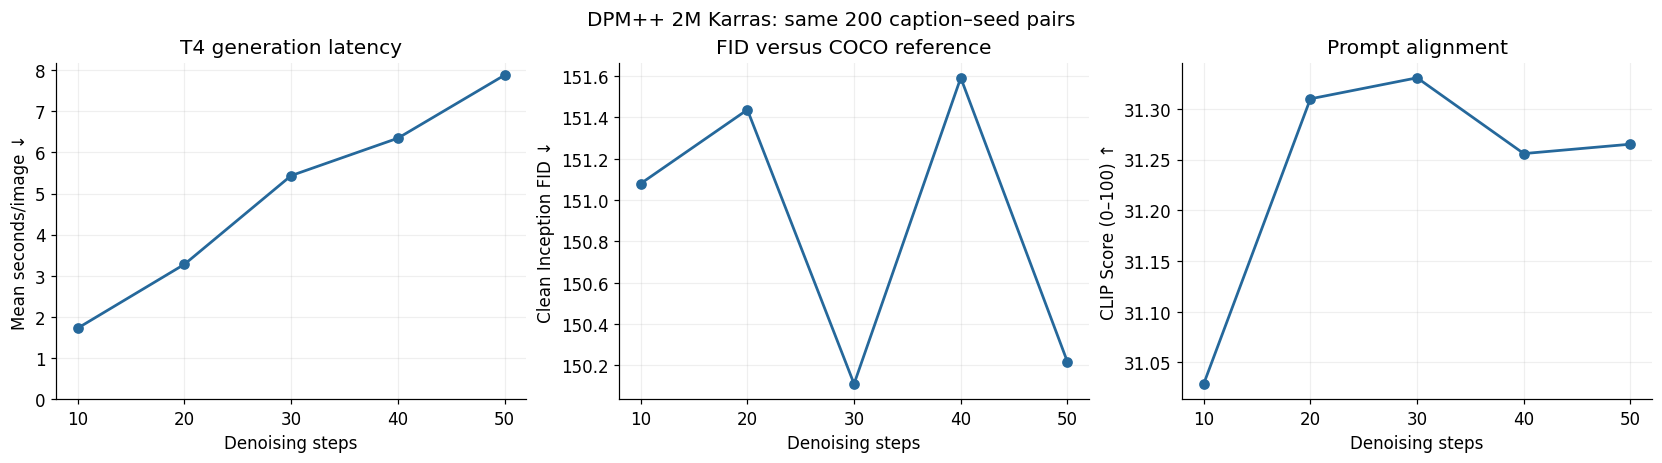

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({'figure.dpi': 110, 'font.size': 11, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': 0.2})
ordered_steps = [10, 20, 30, 40, 50]
step_data = summary.loc[[f'dpmpp_s{steps}' for steps in ordered_steps]]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.1), constrained_layout=True)
for axis, column, title, ylabel in zip(
    axes, ['coursework_latency_mean_s', 'fid_clean', 'clip_score_100'],
    ['T4 generation latency', 'FID versus COCO reference', 'Prompt alignment'],
    ['Mean seconds/image ↓', 'Clean Inception FID ↓', 'CLIP Score (0–100) ↑'],
):
    values = pd.to_numeric(step_data[column], errors='coerce').to_numpy(dtype=float)
    axis.plot(ordered_steps, values, marker='o', color='#25689b', linewidth=1.8)
    axis.set(title=title, xlabel='Denoising steps', ylabel=ylabel, xticks=ordered_steps)
    if not np.isfinite(values).any():
        axis.text(0.5, 0.5, 'Results pending', ha='center', transform=axis.transAxes)
        axis.set_yticks([])
    if column == 'coursework_latency_mean_s':
        axis.set_ylim(bottom=0)
fig.suptitle('DPM++ 2M Karras: same 200 caption–seed pairs', fontsize=13)
plt.show()

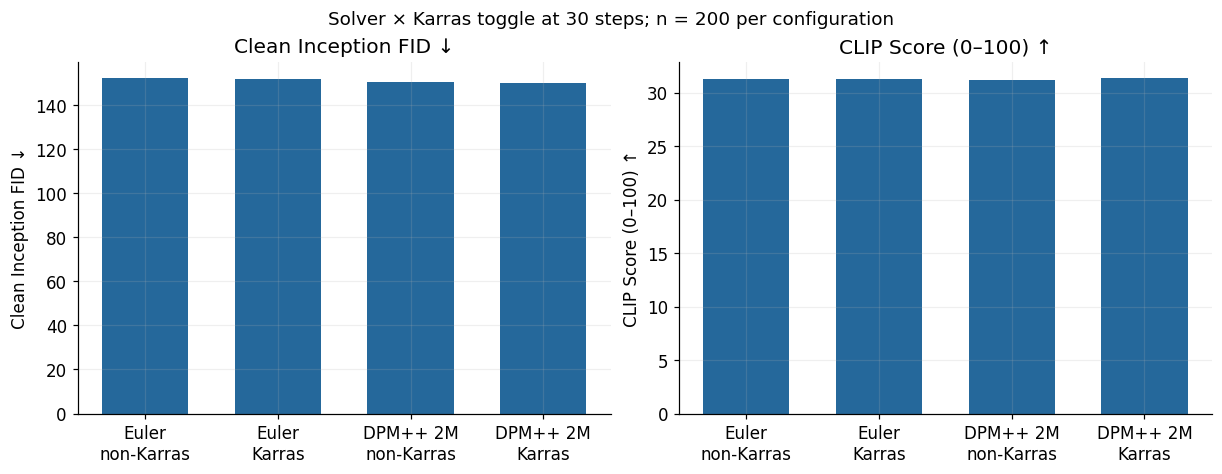

In [ ]:
factorial_batches = ['euler_s30', 'euler_karras_s30', 'dpmpp_nokarras_s30', 'dpmpp_s30']
factorial_labels = ['Euler\nnon-Karras', 'Euler\nKarras', 'DPM++ 2M\nnon-Karras', 'DPM++ 2M\nKarras']
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), constrained_layout=True)
for axis, column, title in zip(axes, ['fid_clean', 'clip_score_100'],
                              ['Clean Inception FID ↓', 'CLIP Score (0–100) ↑']):
    values = pd.to_numeric(summary.loc[factorial_batches, column], errors='coerce').to_numpy(dtype=float)
    axis.bar(range(4), values, color='#25689b', width=0.65)
    axis.set_xticks(range(4), factorial_labels)
    axis.set(title=title, ylabel=title, ylim=(0, None))
    if not np.isfinite(values).any():
        axis.text(0.5, 0.5, 'Results pending', ha='center', transform=axis.transAxes)
        axis.set_yticks([])
fig.suptitle('Solver × Karras toggle at 30 steps; n = 200 per configuration', fontsize=12)
plt.show()

## 9. Paired CLIP uncertainty (optional supporting analysis)

For each step count, resample the same prompt IDs jointly with the 30-step reference.
The 95% percentile interval covers prompt-sampling uncertainty conditional on this
fixed seed set. It does not establish robustness across generation seeds. FID is
not a per-image score and is not bootstrapped in this cell.

In [ ]:
baseline_scores_path = OUTPUT_DIR / 'dpmpp_s30_clip_per_image.csv'
bootstrap_rows = []
if RUN_METRICS and baseline_scores_path.is_file():
    baseline_scores = pd.read_csv(baseline_scores_path).set_index('prompt_id')['clip_raw_100cos']
    for steps in (10, 20, 40, 50):
        scores_path = OUTPUT_DIR / f'dpmpp_s{steps}_clip_per_image.csv'
        if summary.loc[f'dpmpp_s{steps}', 'status'] != 'evaluated' or not scores_path.is_file():
            continue
        scores = pd.read_csv(scores_path).set_index('prompt_id')['clip_raw_100cos']
        assert scores.index.is_unique and baseline_scores.index.is_unique
        assert set(scores.index) == set(baseline_scores.index) == set(range(200))
        values = scores.sort_index().to_numpy()
        reference = baseline_scores.sort_index().to_numpy()
        indices = np.random.default_rng(6127).integers(0, 200, size=(1000, 200))
        differences = np.maximum(values[indices].mean(axis=1), 0) - np.maximum(reference[indices].mean(axis=1), 0)
        low, high = np.percentile(differences, [2.5, 97.5])
        bootstrap_rows.append({
            'Steps': steps, 'CLIP difference versus 30': max(values.mean(), 0) - max(reference.mean(), 0),
            '95% CI lower': low, '95% CI upper': high, 'Prompts': 200, 'Bootstrap samples': 1000,
        })
if bootstrap_rows:
    bootstrap_table = pd.DataFrame(bootstrap_rows)
    display(bootstrap_table.round(3))
    bootstrap_table.to_csv(OUTPUT_DIR / 'paired_clip_bootstrap.csv', index=False)
else:
    print('Paired intervals require completed CLIP scores for both configurations.')

,Steps,CLIP difference versus 30,95% CI lower,95% CI upper,Prompts,Bootstrap samples
0,10,-0.302,-0.517,-0.089,200,1000
1,20,-0.021,-0.175,0.111,200,1000
2,40,-0.075,-0.161,0.017,200,1000
3,50,-0.065,-0.161,0.034,200,1000


## 10. Section 3.3/3.4 notes and Member C handoff

**3.3 Sampling Strategy Comparison — suggested opening:** We compare DDIM,
Euler and DPM++ 2M sampling for Stable Diffusion v1.5 at 30 inference steps.
All methods use the same 200 COCO val2017 caption–seed pairs, CFG 7.5,
512×512 resolution and fp16 on an NVIDIA T4. A 2×2 Euler/DPM++ comparison
with Karras enabled/disabled examines solver and schedule components. We measure
clean-fid Inception-v3 FID against the 200 reference images, CLIP ViT-B/32
image–caption alignment and generation latency. Inspect the saved sigma grids
before claiming a perfectly isolated solver effect.

**3.4 Hyperparameter Analysis — suggested opening:** We vary DPM++ 2M Karras
inference steps over 10, 20, 30, 40 and 50, reusing the existing 30-step batch.
The same prompts and `seed = 1000 + prompt_id` hold prompt/seed variation fixed.
Guidance scale, resolution, precision, GPU and software remain fixed. We compare
latency, FID and CLIP to identify speed–quality trade-offs and diminishing returns.

**Timing explanation:** The three 30-step baseline samplers make 30 U-Net forward
calls; that computation dominates inference. DPM++ 2M reuses previous predictions
for its multistep update. Karras changes noise-level placement without adding
iterations. Thus baseline runtimes are nearly equal, with small differences from
scheduler overhead and GPU variability. Low-step quality needs measured evidence;
only DPM++ has a step sweep here.

**Latency across step counts:** the logged 30-step latency comes from Member A's session
and the 10/20/40/50-step latencies from Member B's. Quote speedups across step counts
from the same-session columns of `step_tradeoffs.csv`; if that check was skipped, state
the cross-session caveat beside Table 2.

**B discussion checklist:** interpret numerical contrasts, speedups and quality changes;
check metric disagreements and paired CLIP uncertainty; identify a measured candidate
for fewer-step inference if results support it. Disclose historical unknown model
revision, fixed seeds, exploratory 200-image FID and any differing sigma grids.
No winner or improvement is asserted before metrics run.

The official brief's at-least-two-methods criterion is interpreted here as comparison
of sampling methods, as planned in TR.docx; the brief does not explicitly adjudicate
variants sharing one pretrained architecture. Member C retains final visualizations,
qualitative examples, limitations, future extensions and document integration.


### Consolidate the Member C handoff

This CPU-only helper joins the stored per-prompt CLIP scores and recorded generation
times to the completed batch FID values. It validates all nine 200-image batches.
The 20-prompt same-session timing recheck remains a separate CSV; its records are
not pooled with the 200-image generation logs.

The three consolidated files are written to `results/`; the checksum manifest goes to
`results/evaluation_details/`. If `src/consolidate_member_b_results.py` is not present,
the cell leaves the existing files untouched and says so.


In [ ]:
consolidator = PROJECT_ROOT / 'src/consolidate_member_b_results.py'
if not (summary['status'] == 'evaluated').all():
    print('Consolidation skipped: all nine evaluated batches are required. Existing exports are retained.')
elif not consolidator.is_file():
    print(f'Consolidation skipped: {consolidator.name} is not in src/. The existing evaluation_* files '
          'in results/ are left as they are and are not refreshed from this run.')
else:
    subprocess.run([sys.executable, str(consolidator),
                    '--project-root', str(PROJECT_ROOT)], check=True, cwd=PROJECT_ROOT)
    display(Markdown((HANDOFF_DIR / 'evaluation_summary.md').read_text(encoding='utf-8')))


In [ ]:
completed = int((summary['status'] == 'evaluated').sum())
display(Markdown(f'**Member C handoff:** `{HANDOFF_DIR}`\n\n'
                 f'Completed metric batches: **{completed}/9**. '
                 'Use evaluation_summary.csv for batch metrics, table2_step_ablation.csv for the step study, '
                 'evaluation_raw_results.csv for image records and evaluation_summary.md for the two tables. '
                 'Breakdowns are in evaluation_details/, including step_tradeoffs.csv and the separate '
                 'timing recheck in same_session_timing_per_prompt.csv. '
                 'Final visuals and report integration belong to Member C.'))


## Reruns and recovery

- **Active generation:** do not execute setup or metrics alongside it. Wait for the
  process to finish and remove its own lock normally.
- **Disconnected runtime:** confirm whether generation is still running before restarting.
  A lock alone does not prove a process is dead. Never delete the lock automatically.
- **Confirmed stopped process with a stale lock:** use the generation CLI's explicit
  `--recover-stale-lock` flag, retaining the same project/mode/steps. Known live local
  lock owners are refused. A legacy empty lock needs operator confirmation that its
  original Colab process has stopped. Unknown lock contents require inspection.
- **Legacy incomplete batch with unknown revision:** review `revision_adoption.json`
  policy before enabling `ADOPT_UNKNOWN_REVISION`. Existing unknown images retain
  their historical status. Prefer allowing the current job to complete normally.
- **Interrupted helper image commit:** matching journals recover committed PNG/log rows;
  owned truncated files and temporary writes are cleaned safely on restart. Unowned
  or unexplained files are preserved and cause a stop.
- **Metrics interrupted/OOM:** reconnect to a T4 and rerun, using batch size 16 if needed.
  Completed FID and matching CLIP chunks persist in `results/evaluation_details/cache/`.
  If that folder has been removed, a new metric run recomputes features and scores.
- **Different GPU/software:** restore the T4 and Member A's saved versions before timing.
- **Fresh runtime:** with `INSTALL_GENERATION_ENV=True` the dependency cell installs Member A's
  recorded versions when they differ. If it asks for a restart, use Runtime → Restart session
  and run from the top.
- **CLIP projection check fails:** do not run the metrics; the installed Transformers version
  returns different features from the ones the evaluator expects.
- **Metrics stop with `ValueError: Imaginary component`:** clean-fid's matrix square root failed
  on the rank-deficient 200-image covariance. The Inception features are cached and a rerun
  repeats the same computation, so this needs a fallback FID computed from the cached features
  in a notebook cell. Do not edit `src/evaluate_member_b.py`; setup rejects an edited helper.
- **Save executed outputs:** use File → Save a copy in Drive for the numeric handoff.

### Primary references and pinned repositories

- [Official SD v1.5 pinned repository](https://huggingface.co/stable-diffusion-v1-5/stable-diffusion-v1-5/tree/451f4fe16113bff5a5d2269ed5ad43b0592e9a14)
- [Official CLIP pinned commit](https://huggingface.co/openai/clip-vit-base-patch32/commit/3d74acf9a28c67741b2f4f2ea7635f0aaf6f0268)
- [clean-fid protocol/API](https://github.com/GaParmar/clean-fid)
- [TorchMetrics CLIPScore aggregation](https://github.com/Lightning-AI/torchmetrics/blob/master/src/torchmetrics/functional/multimodal/clip_score.py)
- [DPM-Solver multistep scheduler](https://huggingface.co/docs/diffusers/api/schedulers/multistep_dpm_solver)
- [Finite-sample FID bias, Chong and Forsyth](https://arxiv.org/abs/1911.07023)
